# UAV tracking in uplink ISAC: paper reproduction + UE-motion clutter extension (single notebook)
All data is **synthetic** (your bundle + generators in this notebook). Nothing here is the paper's dataset; label every figure "our simulation".

**You only need to upload ONE file:** `synthetic_uav_isac_research_bundle.zip` (a copy named `... (1).zip` is fine).
All code files are written by cells in Part A. Use a **CPU** runtime (GPU gives no benefit). Run cells top to bottom.

| Part | What it does | Rough time (CPU) |
|---|---|---|
| A | upload bundle, write all code files, sanity checks | 1-2 min |
| B | paper reproduction: EKF, IMM(2), IMM(3), CKN, learning-aided EKF (Fig. 5 style) | 20-40 min |
| C | ablation (Fig. 6 idea) + confidence intervals | 5-10 min |
| D | novelty: UE motion breaks the zero-Doppler clutter notch (sweep + figures) | 15-30 min |
| E | paper pipeline vs our pipeline (learning-aided EKF on the clutter measurements) | 20-35 min |
| F | save everything to Google Drive | 1 min |

Times are rough guesses from a 1-core test machine; Colab may differ. Every stage caches its results, so if the runtime disconnects, rerun Part A and then only the stage that did not finish.

## Part A. Setup

In [ ]:
from google.colab import files
up = files.upload()   # choose synthetic_uav_isac_research_bundle.zip  (the ONLY upload needed)

Saving synthetic_uav_isac_research_bundle.zip to synthetic_uav_isac_research_bundle.zip


In [ ]:
!mkdir -p /content/bundle /content/code
!unzip -o -q "$(ls -t synthetic_uav_isac_research_bundle*.zip | head -1)" -d /content/bundle
!ls /content/bundle

clutter_measurements.csv      scenario_metadata.json   ue_positions.csv
generate_uav_isac_dataset.py  target_measurements.csv
README.md		      uav_ground_truth.csv


### Write the code files (11 small cells; just run them)
Each cell saves one Python file into `/content/code`.
- `data_port.py`: bit-exact port of the bundle generator + extensions (controlled UE speed, boresight rotation)
- `tracker.py`: measurement model + analytic Jacobian, EKF, learning-aided EKF, CKN-style filter
- `imm.py`, `pipeline.py`, `run_fig5.py`: IMM baselines, training utilities, Fig. 5 runner
- `clutter_exp.py`, `run_clutter.py`: novelty experiment (signal model, clutter filters, IAA, sweep)
- `run_ablation.py`, `run_stats.py`, `run_tracking_compare.py`: ablation, confidence intervals, paper-vs-ours pipeline

In [ ]:
%%writefile /content/code/data_port.py
import numpy as np
C=299792458.; FC=3.5e9; LAM=C/FC; BS=np.array([0.,0.,25.]); DT=.1

def unit(a): return a/(np.linalg.norm(a)+1e-12)
def ang(a): return np.arctan2(a[1],a[0]),np.arctan2(a[2],np.hypot(a[0],a[1]))

def simulate(nt, mode_fn, mob_fn, seed, nf=100, nu=4, ue_speed=None):
    """Faithful port of generate_uav_isac_dataset.py (same RNG call order, incl. clutter draws)."""
    rng=np.random.default_rng(seed); rng_ue=np.random.default_rng(seed+999)   # rng_ue only used when ue_speed is set
    out={k:[] for k in ['ue_vel','p','v','ue_true','ue_hat','snr','r_meas','r_true','rate_true','dop_meas','az_meas','el_meas','sig_r','sig_d','sig_a']}
    modes=[]
    for tr in range(nt):
        mode=mode_fn(tr); mob=mob_fn(tr); modes.append(mode)
        ue0=np.c_[rng.uniform(-300,300,nu),rng.uniform(-300,300,nu),rng.uniform(1,2,nu)]
        uev=rng.normal(0,.5,(nu,3))
        if mob=='stationary': uev[:]=0
        elif mob=='walking': uev*=2
        else: uev*=12
        if ue_speed is not None:   # controlled UE speed (random horizontal heading); consumes NO draws from the main stream -> UAV/noise realisations stay identical across speeds
            hd=rng_ue.uniform(-np.pi,np.pi,nu); uev=ue_speed*np.stack([np.cos(hd),np.sin(hd),np.zeros(nu)],1)
        out['ue_vel'].append(uev.copy())
        p=np.zeros((nf,3));v=np.zeros((nf,3))
        p[0]=[rng.uniform(-100,100),rng.uniform(-100,100),rng.uniform(60,130)];h=rng.uniform(-np.pi,np.pi);sp=rng.uniform(8,18);v[0]=[sp*np.cos(h),sp*np.sin(h),rng.uniform(-1,1)]
        for t in range(1,nf):
            prev=v[t-1].copy()
            if mode=='high':
                turn=[0,.055,-.07,.09][(t//12)%4];c,s=np.cos(turn),np.sin(turn);prev[:2]=[c*prev[0]-s*prev[1],s*prev[0]+c*prev[1]];a=rng.normal(0,1.4,3);a[2]=rng.normal(0,.45)
            elif mode=='low': a=rng.normal(0,.45,3);a[2]=rng.normal(0,.12)
            else: a=rng.normal(0,.9,3);a[2]=rng.normal(0,.3)
            v[t]=prev+a*DT;hh=np.linalg.norm(v[t,:2])
            if hh>28:v[t,:2]*=28/hh
            if hh<3:v[t,:2]*=3/max(hh,1e-9)
            v[t,2]=np.clip(v[t,2],-4,4);p[t]=p[t-1]+v[t]*DT
            if p[t,2]<35:p[t,2]=35;v[t,2]=abs(v[t,2])
            if p[t,2]>180:p[t,2]=180;v[t,2]=-abs(v[t,2])
        A={k:np.zeros((nf,nu)) for k in ['snr','r_meas','r_true','rate_true','dop_meas','az_meas','el_meas','sig_r','sig_d','sig_a']}
        UT=np.zeros((nf,nu,3));UH=np.zeros((nf,nu,3))
        for t in range(nf):
            tm=t*DT
            for i in range(nu):
                up=ue0[i]+uev[i]*tm
                UT[t,i]=up; UH[t,i]=up+rng.normal(0,np.sqrt(5),3)   # same stream order as 3 scalar draws
                d1v=p[t]-up;d2v=p[t]-BS;d1=np.linalg.norm(d1v);d2=np.linalg.norm(d2v);path=d1+d2
                if t:
                    uprev=ue0[i]+uev[i]*((t-1)*DT);pr=np.linalg.norm(p[t-1]-uprev)+np.linalg.norm(p[t-1]-BS);rate=(path-pr)/DT
                else: rate=np.dot(unit(d1v),v[t]-uev[i])+np.dot(unit(d2v),v[t])
                dop=-rate/LAM;az,el=ang(d2v);snr=float(rng.choice([0,5,10,20]));scale=10**(-snr/20);rs=1+2*scale;ds=1+3*scale;aas=np.deg2rad(.5+2.5*scale)
                A['snr'][t,i]=snr;A['r_true'][t,i]=path;A['r_meas'][t,i]=path+rng.normal(0,rs);A['rate_true'][t,i]=rate
                A['dop_meas'][t,i]=dop+rng.normal(0,ds);A['az_meas'][t,i]=az+rng.normal(0,aas);A['el_meas'][t,i]=el+rng.normal(0,aas)
                A['sig_r'][t,i]=rs;A['sig_d'][t,i]=ds;A['sig_a'][t,i]=aas
                for q in range(3):   # clutter draws consumed only to keep the RNG stream identical
                    rng.uniform(-350,350);rng.uniform(-350,350);rng.uniform(0,30);rng.normal(0,2);rng.normal(-8,4)
        out['p'].append(p);out['v'].append(v);out['ue_true'].append(UT);out['ue_hat'].append(UH)
        for k in A: out[k].append(A[k])
    out={k:np.array(v_) for k,v_ in out.items()}; out['mode']=np.array(modes); return out

def load_bundle(folder, maneuver='high'):
    """Read the user's bundle CSVs into the same array layout as simulate()."""
    import pandas as pd, os
    gt = pd.read_csv(os.path.join(folder,'uav_ground_truth.csv')).sort_values(['trajectory_id','frame'])
    tg = pd.read_csv(os.path.join(folder,'target_measurements.csv')).sort_values(['trajectory_id','frame','ue_id'])
    ue = pd.read_csv(os.path.join(folder,'ue_positions.csv')).sort_values(['trajectory_id','frame','ue_id'])
    nt, nf, nu = gt.trajectory_id.nunique(), gt.frame.nunique(), tg.ue_id.nunique()
    R = lambda df, cols, tail: df[cols].values.reshape(nt, nf, *tail)
    D = dict(p=R(gt,['px_m','py_m','pz_m'],(3,)), v=R(gt,['vx_mps','vy_mps','vz_mps'],(3,)),
             ue_true=R(ue,['ue_x_true_m','ue_y_true_m','ue_z_true_m'],(nu,3)), ue_hat=R(ue,['ue_x_noisy_m','ue_y_noisy_m','ue_z_noisy_m'],(nu,3)),
             snr=R(tg,['snr_db'],(nu,)), r_meas=R(tg,['bistatic_path_measured_m'],(nu,)), r_true=R(tg,['bistatic_path_true_m'],(nu,)),
             rate_true=R(tg,['path_rate_true_mps'],(nu,)), dop_meas=R(tg,['doppler_measured_hz'],(nu,)),
             az_meas=R(tg,['azimuth_measured_rad'],(nu,)), el_meas=R(tg,['elevation_measured_rad'],(nu,)),
             sig_r=R(tg,['range_noise_sigma_m'],(nu,)), sig_d=R(tg,['doppler_noise_sigma_hz'],(nu,)), sig_a=R(tg,['angle_noise_sigma_rad'],(nu,)))
    D['mode'] = gt.groupby('trajectory_id').maneuverability.first().values
    if maneuver is not None:
        sel = np.where(D['mode'] == maneuver)[0]
        D = {k: v[sel] for k, v in D.items()}
    return D


def boresight_rotate(D):
    """Aim the array boresight (+x of the BS-local frame) at each trajectory's mean UAV bearing: rotate all positions/velocities about z and shift azimuths.
    Emulates deploying each scenario in the array's own frame (the paper's UPA only sees the front half-space)."""
    p = D['p']-BS; az = np.arctan2(p[..., 1], p[..., 0])
    alpha = np.arctan2(np.sin(az).mean(1), np.cos(az).mean(1))                 # [N]
    c, s_ = np.cos(-alpha), np.sin(-alpha)
    def rot(a, off):                                                           # a: [N,...,3]; rotate about the BS axis (off = BS position)
        sh = (-1,)+(1,)*(a.ndim-2); cc, ss = c.reshape(sh), s_.reshape(sh)
        x, y = a[..., 0]-off[0], a[..., 1]-off[1]
        return np.stack([cc*x-ss*y+off[0], ss*x+cc*y+off[1], a[..., 2]], -1)
    O = dict(D)
    for k in ('p', 'ue_true', 'ue_hat'): O[k] = rot(D[k], BS)
    sh = (-1,)+(1,)*(D['v'].ndim-2); cc, ss = c.reshape(sh), s_.reshape(sh)
    O['v'] = np.stack([cc*D['v'][..., 0]-ss*D['v'][..., 1], ss*D['v'][..., 0]+cc*D['v'][..., 1], D['v'][..., 2]], -1)
    O['az_meas'] = D['az_meas']-alpha.reshape(-1, 1, 1)
    O['alpha'] = alpha
    off = np.abs(np.angle(np.exp(1j*(az-alpha[:, None])))).max(1)               # max bearing offset from boresight per trajectory
    O['max_offset'] = off
    return O

def simulate_front(n, seed, max_offset_deg=85., chunk=None):
    """Generate n high-maneuver/walking-UE trajectories that stay inside the front sector (rejection sampling), then aim the boresight."""
    keep, k = [], 0
    while sum(len(x['p']) for x in keep) < n:
        D = boresight_rotate(simulate(chunk or max(n, 8), lambda tr: 'high', lambda tr: 'walking', seed+k)); k += 1000
        ok = np.where(D['max_offset'] < np.deg2rad(max_offset_deg))[0]
        keep.append({kk: (v[ok] if isinstance(v, np.ndarray) and len(v) == len(D['p']) else v) for kk, v in D.items()})
    out = {kk: np.concatenate([x[kk] for x in keep])[:n] for kk in keep[0] if isinstance(keep[0][kk], np.ndarray)}
    return out

Writing /content/code/data_port.py


In [ ]:
%%writefile /content/code/tracker.py
import numpy as np, torch, torch.nn as nn, torch.nn.functional as Fn, math
from data_port import LAM, BS, DT
torch.set_default_dtype(torch.float64)
DEV = 'cpu'

# ----------------------------------------------------------------- data prep
def prep(D, Ks):
    """Raw simulator arrays -> BS-local torch tensors for a given number of selected UEs Ks (top-Ks by SNR)."""
    N, L, U = D['snr'].shape
    key = -D['snr'] + 1e-6*np.arange(U)                     # top-SNR first, ties broken by UE index (deterministic)
    idx = np.argsort(key, axis=-1, kind='stable')[..., :Ks]
    g = lambda a: np.take_along_axis(a, idx, axis=2)
    ue = np.take_along_axis(D['ue_hat'] - BS, idx[..., None], axis=2)       # estimated UE positions, BS-local
    r, v = g(D['r_meas']), -g(D['dop_meas'])*LAM                              # bistatic path [m], bistatic rate [m/s] (dop=-rate/lam)
    sr, sv, sa = g(D['sig_r']), g(D['sig_d'])*LAM, g(D['sig_a'])
    az, el = g(D['az_meas']), g(D['el_meas'])
    psi_i, phi_i = np.sin(az)*np.cos(el), np.sin(el)                          # direction cosines: psi=y/|p|, phi=z/|p|
    spsi = sa*np.sqrt(np.cos(az)**2*np.cos(el)**2 + np.sin(az)**2*np.sin(el)**2)
    sphi = sa*np.abs(np.cos(el))
    w1, w2 = 1/spsi**2, 1/sphi**2                                             # inverse-variance fusion across UEs (stand-in for MUSIC's joint estimate)
    psi, phi = (w1*psi_i).sum(-1)/w1.sum(-1), (w2*phi_i).sum(-1)/w2.sum(-1)
    spsi_c, sphi_c = 1/np.sqrt(w1.sum(-1)), 1/np.sqrt(w2.sum(-1))
    T = lambda a: torch.tensor(a, dtype=torch.float64)
    out = dict(ue=T(ue), z=T(np.concatenate([r, v, psi[..., None], phi[..., None]], -1)),
               sig=T(np.concatenate([sr, sv, spsi_c[..., None], sphi_c[..., None]], -1)),
               x_gt=T(np.concatenate([D['p']-BS, D['v']], -1)), Ks=Ks)
    out['x0'], out['Sig0'] = init_state(out)
    return out

def init_state(d):
    """Geometric initialisation at frame 0: direction from (psi,phi) [x-sign ambiguity resolved by ranges], rho by 1-D grid search on bistatic ranges, v by ridge LS on rates."""
    ue, z, sig = d['ue'][:, 0], d['z'][:, 0], d['sig'][:, 0]; B, K = ue.shape[:2]
    r, rate, psi, phi = z[:, :K], z[:, K:2*K], z[:, -2], z[:, -1]
    rho = torch.arange(10., 800., 1.)                                         # [G]
    ux = torch.sqrt(torch.clamp(1-psi**2-phi**2, min=1e-9))
    best, bp = torch.full((B,), 1e18), torch.zeros(B, 3)
    for sgn in (1., -1.):
        u = torch.stack([sgn*ux, psi, phi], -1)                               # [B,3]
        p = rho[None, :, None]*u[:, None]                                     # [B,G,3]
        rr = (p[:, :, None]-ue[:, None]).norm(dim=-1) + rho[None, :, None]    # [B,G,K]
        cost = (((rr-r[:, None])/sig[:, None, :K])**2).sum(-1)                # [B,G]
        c, gi = cost.min(1); m = c < best
        best = torch.where(m, c, best); bp = torch.where(m[:, None], p[torch.arange(B), gi], bp)
    p0 = bp
    dd = p0[:, None]-ue; e = dd/dd.norm(dim=-1, keepdim=True); G = e + (p0/p0.norm(dim=-1, keepdim=True))[:, None]
    W = 1/sig[:, K:2*K]**2
    A = torch.einsum('bki,bk,bkj->bij', G, W, G) + torch.eye(3)*(1/10.**2)    # prior v ~ N(0, 10^2 I)
    v0 = torch.linalg.solve(A, torch.einsum('bki,bk,bk->bi', G, W, rate)[..., None])[..., 0]
    Sig0 = torch.zeros(B, 6, 6); Sig0[:, :3, :3] = 10.*torch.eye(3); Sig0[:, 3:, 3:] = torch.linalg.inv(A)
    return torch.cat([p0, v0], -1), Sig0

# ----------------------------------------------------------------- measurement model (paper eq. 18-21) + analytic Jacobian
def meas_model(x, ue):
    """x [B,6] (BS-local), ue [B,K,3] estimated UE positions -> h [B,2K+2], H [B,2K+2,6], plus blocks used by the update module."""
    p, v = x[:, :3], x[:, 3:]; B, K = ue.shape[:2]
    rho = p.norm(dim=-1, keepdim=True); e0 = p/rho
    d = p[:, None]-ue; n = d.norm(dim=-1, keepdim=True); e = d/n
    g = e0[:, None] + e                                                       # [B,K,3]
    r = n[..., 0] + rho; rate = (g*v[:, None]).sum(-1)
    psi, phi = p[:, 1:2]/rho, p[:, 2:3]/rho
    h = torch.cat([r, rate, psi, phi], -1)
    z3 = torch.zeros(B, K, 3)
    Jr = torch.cat([g, z3], -1)
    t0 = (v - (e0*v).sum(-1, keepdim=True)*e0)/rho                            # (I-e0 e0^T) v / rho
    t1 = (v[:, None] - (e*v[:, None]).sum(-1, keepdim=True)*e)/n              # (I-e e^T) v / n
    Jv = torch.cat([t0[:, None]+t1, g], -1)
    yh, zh = torch.tensor([0., 1., 0.]), torch.tensor([0., 0., 1.])
    Jpsi = torch.cat([(yh-psi*e0)/rho, torch.zeros(B, 3)], -1)
    Jphi = torch.cat([(zh-phi*e0)/rho, torch.zeros(B, 3)], -1)
    H = torch.cat([Jr, Jv, Jpsi[:, None], Jphi[:, None]], 1)
    return h, H

F_PB = torch.eye(6); F_PB[:3, 3:] = DT*torch.eye(3)
def q_cv(q):   # white-noise-acceleration process noise for the CV model
    Q = torch.zeros(6, 6); I = torch.eye(3)
    Q[:3, :3] = DT**3/3*q*I; Q[:3, 3:] = DT**2/2*q*I; Q[3:, :3] = DT**2/2*q*I; Q[3:, 3:] = DT*q*I
    return Q

# ----------------------------------------------------------------- neural modules
class PredNet(nn.Module):
    """FC1 -> GRU -> (FC2: state correction, FC3: 21 values -> Cholesky layer -> dSigma)."""
    def __init__(s, hid=64, cov_scale=4.0):
        super().__init__(); s.hid, s.cov_scale = hid, cov_scale
        s.fc1, s.gru, s.fc2, s.fc3 = nn.Linear(12, hid), nn.GRUCell(hid, hid), nn.Linear(hid, 6), nn.Linear(hid, 21)
        s.register_buffer('out_scale', torch.tensor([.1, .1, .1, 1., 1., 1.]))
        s.tri = torch.tril_indices(6, 6); s.is_diag = (s.tri[0] == s.tri[1])
        with torch.no_grad(): s.fc2.weight.mul_(0.1); s.fc2.bias.zero_()
    def forward(s, dxh, dxb, h):
        h = s.gru(torch.relu(s.fc1(torch.cat([dxh, dxb], -1))), h)
        dx = s.fc2(h)*s.out_scale
        c = s.fc3(h); B = c.shape[0]
        diag = torch.softmax(c[:, s.is_diag], -1)*s.cov_scale               # softmax on diagonal -> positive (paper), scaled (our assumption)
        Lm = torch.zeros(B, 6, 6)
        Lm[:, s.tri[0][~s.is_diag], s.tri[1][~s.is_diag]] = c[:, ~s.is_diag]*(0.1*s.cov_scale)
        Lm[:, torch.arange(6), torch.arange(6)] = diag
        return dx, Lm@Lm.transpose(1, 2), h

class UpdNet(nn.Module):
    """Range-velocity submodule (FC4->FC5,FC6) per UE + angle submodule (FC7->FC8,FC9); dR = Xi^T Xi."""
    def __init__(s, df=64, hid=64):
        super().__init__(); s.df = df
        s.fc4, s.fc5, s.fc6 = nn.Linear(14, hid), nn.Linear(hid, df), nn.Linear(hid, df)
        s.fc7, s.fc8, s.fc9 = nn.Linear(14, hid), nn.Linear(hid, df), nn.Linear(hid, df)
    def forward(s, innov, H, sig):
        B, m, _ = H.shape; K = (m-2)//2
        n = torch.asinh(innov/sig)                                           # normalised, outlier-compressed innovations
        rv_in = torch.cat([n[:, :K, None], n[:, K:2*K, None], H[:, :K], H[:, K:2*K]], -1)      # [B,K,14]
        hr = torch.relu(s.fc4(rv_in)); eta_r, eta_v = s.fc5(hr), s.fc6(hr)                   # [B,K,df] each (per-UE, shared weights -> any K)
        an_in = torch.cat([n[:, -2:], H[:, -2].reshape(B, 6), H[:, -1].reshape(B, 6)], -1)    # [B,14]
        ha = torch.relu(s.fc7(an_in)); eta_psi, eta_phi = s.fc8(ha), s.fc9(ha)
        Xi_T = torch.cat([eta_r, eta_v, eta_psi[:, None], eta_phi[:, None]], 1)/math.sqrt(s.df)  # [B,2K+2,df]  (= Xi^T)
        dR = Xi_T@Xi_T.transpose(1, 2)                                       # Xi^T Xi -> PSD Gram matrix [B,m,m]
        return sig[:, :, None]*dR*sig[:, None, :]                            # rescale to physical units (our assumption)

class CKNUpdate(nn.Module):
    """CKN-style baseline (our interpretation): fixed input size, GRU, Cholesky-parametrised innovation-covariance correction. One model per Ks."""
    def __init__(s, m, hid=64):
        super().__init__(); s.m = m
        s.fc1, s.gru, s.fc2 = nn.Linear(m+12, hid), nn.GRUCell(hid, hid), nn.Linear(hid, m*(m+1)//2)
        s.tri = torch.tril_indices(m, m); s.is_diag = (s.tri[0] == s.tri[1])
        with torch.no_grad(): s.fc2.weight.mul_(0.1)
    def forward(s, innov, sig, dxh, dxb, h):
        h = s.gru(torch.relu(s.fc1(torch.cat([torch.asinh(innov/sig), dxh, dxb], -1))), h)
        c = s.fc2(h); B = c.shape[0]; Lm = torch.zeros(B, s.m, s.m)
        Lm[:, s.tri[0], s.tri[1]] = torch.where(s.is_diag, Fn.softplus(c-2.), c*0.1)
        return sig[:, :, None]*(Lm@Lm.transpose(1, 2))*sig[:, None, :], h

# ----------------------------------------------------------------- the filter (EKF / learning-aided EKF / CKN, selected by flags)
class Tracker(nn.Module):
    def __init__(s, pred='phys', upd='none', q=10.0, Ks_ckn=None, gate=None, gate_start=3):
        super().__init__(); s.pred_mode, s.upd_mode = pred, upd
        s.gate, s.gate_start = gate, gate_start      # optional validation gate on the bistatic-velocity measurements (chi-square threshold, 1 dof)
        s.register_buffer('Q', q_cv(q))
        s.pred = PredNet() if pred == 'nn' else None
        s.upd = UpdNet() if upd == 'gram' else (CKNUpdate(2*Ks_ckn+2) if upd == 'ckn' else None)
    def forward(s, d, return_cov=False):
        ue, z, sig, x = d['ue'], d['z'], d['sig'], d['x0'].clone()
        B, L = z.shape[:2]
        Sig = d['Sig0'].clone()
        hp = torch.zeros(B, 64); hu = torch.zeros(B, 64)
        dxh = torch.zeros(B, 6); dxb = torch.zeros(B, 6)
        xs, Ss = [x], [Sig]
        for l in range(1, L):
            xp = x@F_PB.T; Sp = F_PB@Sig@F_PB.T
            if s.pred is not None:
                dx, dS, hp = s.pred(dxh, dxb, hp); xp = xp+dx; Sp = Sp+dS
            else: Sp = Sp+s.Q
            hx, H = meas_model(xp, ue[:, l]); innov = z[:, l]-hx
            R = torch.diag_embed(sig[:, l]**2)
            S = H@Sp@H.transpose(1, 2)+R
            if s.upd_mode == 'gram': S = S+s.upd(innov, H, sig[:, l])
            elif s.upd_mode == 'ckn': dR, hu = s.upd(innov, sig[:, l], dxh, dxb, hu); S = S+dR
            S = 0.5*(S+S.transpose(1, 2))
            Lc = torch.linalg.cholesky(S)
            K = torch.cholesky_solve(H@Sp, Lc).transpose(1, 2)             # K = Sp H^T S^-1 (no explicit inverse)
            xn = xp+(K@innov[..., None])[..., 0]
            Sn = Sp-K@S@K.transpose(1, 2); Sn = 0.5*(Sn+Sn.transpose(1, 2))+1e-9*torch.eye(6)
            dxh, dxb = xn-xp, xn-x
            x, Sig = xn, Sn; xs.append(x); Ss.append(Sig)
        X = torch.stack(xs, 1)
        return (X, torch.stack(Ss, 1)) if return_cov else X

def loss_fn(X, Sg, xgt, rho=(1., 1., 0.02)):
    e = (X-xgt)[:, 1:]; S = Sg[:, 1:]
    Lpos = torch.sqrt((e[..., :3]**2).sum(-1).mean()); Lvel = torch.sqrt((e[..., 3:]**2).sum(-1).mean())
    Lc = torch.linalg.cholesky(S)
    nll = ((torch.cholesky_solve(e[..., None], Lc)*e[..., None]).sum((-1, -2)) + 2*torch.log(torch.diagonal(Lc, dim1=-2, dim2=-1)).sum(-1)).mean()
    return rho[0]*Lpos+rho[1]*Lvel+rho[2]*nll, Lpos.item(), Lvel.item(), nll.item()

def errors(X, xgt):
    e = (X-xgt)[:, 1:]
    return e[..., :3].norm(dim=-1).reshape(-1).numpy(), e[..., 3:].norm(dim=-1).reshape(-1).numpy()

Writing /content/code/tracker.py


In [ ]:
%%writefile /content/code/imm.py
import numpy as np
from data_port import DT
# Common 10-state for all IMM models: [p(3), v(3), a(3), omega]. Only (p,v) are observed.
def _np_meas(x, ue):
    p, v = x[:3], x[3:6]; rho = np.linalg.norm(p); e0 = p/rho
    d = p-ue; n = np.linalg.norm(d, axis=1, keepdims=True); e = d/n; g = e0+e; K = len(ue)
    h = np.concatenate([n[:, 0]+rho, g@v, [p[1]/rho, p[2]/rho]])
    H = np.zeros((2*K+2, 10)); H[:K, :3] = g
    t0 = (v-(e0@v)*e0)/rho; t1 = (v-(e@v)[:, None]*e)/n
    H[K:2*K, :3] = t0+t1; H[K:2*K, 3:6] = g
    H[-2, :3] = (np.array([0, 1., 0])-h[-2]*e0)/rho; H[-1, :3] = (np.array([0, 0, 1.])-h[-1]*e0)/rho
    return h, H

def _f(x, kind):
    p, v, a, w = x[:3].copy(), x[3:6].copy(), x[6:9].copy(), x[9]
    if kind == 'CV': return np.concatenate([p+v*DT, v, np.zeros(3), [0.]])
    if kind == 'CA': return np.concatenate([p+v*DT+0.5*a*DT**2, v+a*DT, a, [0.]])
    # CT (horizontal turn with unknown turn rate omega)
    wt = w*DT
    if abs(w) < 1e-6: s, c = DT, 0.5*w*DT**2
    else: s, c = np.sin(wt)/w, (1-np.cos(wt))/w
    cw, sw = np.cos(wt), np.sin(wt)
    pn = np.array([p[0]+s*v[0]-c*v[1], p[1]+c*v[0]+s*v[1], p[2]+v[2]*DT])
    vn = np.array([cw*v[0]-sw*v[1], sw*v[0]+cw*v[1], v[2]])
    return np.concatenate([pn, vn, np.zeros(3), [w]])

def _jac(x, kind, eps=1e-6):
    J = np.zeros((10, 10))
    for i in range(10):
        dx = np.zeros(10); dx[i] = eps*max(1., abs(x[i]))
        J[:, i] = (_f(x+dx, kind)-_f(x-dx, kind))/(2*dx[i])
    return J

def _Q(kind, s):
    Q = np.zeros((10, 10)); I3 = np.eye(3)
    if kind == 'CV':
        q = 1.0*s; B = q*np.array([[DT**3/3, DT**2/2], [DT**2/2, DT]]); Q[:6, :6] = np.kron(B, I3)
    elif kind == 'CA':
        q = 50.0*s; B = q*np.array([[DT**5/20, DT**4/8, DT**3/6], [DT**4/8, DT**3/3, DT**2/2], [DT**3/6, DT**2/2, DT]]); Q[:9, :9] = np.kron(B, I3)
    else:
        q = 1.0*s; B = q*np.array([[DT**3/3, DT**2/2], [DT**2/2, DT]]); Q[:6, :6] = np.kron(B, I3); Q[9, 9] = 0.3*s*DT
    Q[6:9, 6:9] += 1e-6*np.eye(3)*(kind != 'CA'); Q[9, 9] += 1e-8
    return Q

def run_imm(d, kinds=('CV', 'CT'), s=1.0, p_stay=0.9):
    """d: dict from tracker.prep (torch). Returns X [N,L,6] (BS-local state estimates)."""
    ue, z, sig, x0, S0 = [d[k].numpy() for k in ('ue', 'z', 'sig', 'x0', 'Sig0')]
    N, L = z.shape[:2]; M = len(kinds)
    Pi = np.full((M, M), (1-p_stay)/max(M-1, 1)); np.fill_diagonal(Pi, p_stay)
    Qs = [_Q(k, s) for k in kinds]; out = np.zeros((N, L, 6))
    for n in range(N):
        xj = [np.concatenate([x0[n], np.zeros(4)]) for _ in range(M)]
        Pj = []
        for _ in range(M):
            P = np.zeros((10, 10)); P[:6, :6] = S0[n]; P[6:9, 6:9] = np.eye(3)*4.; P[9, 9] = 0.1; Pj.append(P)
        mu = np.full(M, 1./M); out[n, 0] = x0[n]
        for l in range(1, L):
            cbar = Pi.T@mu; mix = (Pi*mu[:, None])/cbar[None, :]
            lik = np.zeros(M); xn, Pn = [], []
            for j, k in enumerate(kinds):
                xm = sum(mix[i, j]*xj[i] for i in range(M))
                Pm = sum(mix[i, j]*(Pj[i]+np.outer(xj[i]-xm, xj[i]-xm)) for i in range(M))
                F = _jac(xm, k); xp = _f(xm, k); Pp = F@Pm@F.T+Qs[j]
                h, H = _np_meas(xp, ue[n, l]); y = z[n, l]-h
                R = np.diag(sig[n, l]**2); S = H@Pp@H.T+R; S = 0.5*(S+S.T)
                Kg = np.linalg.solve(S, H@Pp).T; xu = xp+Kg@y
                IKH = np.eye(10)-Kg@H; Pu = IKH@Pp@IKH.T+Kg@R@Kg.T; Pu = 0.5*(Pu+Pu.T)
                sgn, ld = np.linalg.slogdet(S)
                lik[j] = np.exp(-0.5*(y@np.linalg.solve(S, y)+ld+len(y)*np.log(2*np.pi)))
                xn.append(xu); Pn.append(Pu)
            mu = lik*cbar; mu = mu/mu.sum() if mu.sum() > 1e-300 else cbar
            mu = np.clip(mu, 1e-4, None); mu /= mu.sum()
            xj, Pj = xn, Pn; out[n, l] = sum(mu[j]*xj[j][:6] for j in range(M))
    return out

Writing /content/code/imm.py


In [ ]:
%%writefile /content/code/pipeline.py
import time, copy, numpy as np, torch
from data_port import simulate, load_bundle
from tracker import *
from imm import run_imm

def sub(d, idx): return {k: (v[idx] if torch.is_tensor(v) else v) for k, v in d.items()}
def rm(a): return float(np.sqrt((a**2).mean()))

def evaluate_model(model, d):
    with torch.no_grad(): X = model(d)
    return errors(X, d['x_gt'])

def val_metric(model, vsets):
    s = 0.
    for d in vsets.values():
        ep, ev = evaluate_model(model, d); s += rm(ep)+rm(ev)
    return s/len(vsets)

def fit(model, params, tsets, vsets, iters, lr, bs=32, eval_every=20, rho=(1., 1., 0.02), tag='', log=print):
    opt = torch.optim.Adam(params, lr); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, iters, eta_min=lr*0.1)
    keys = list(tsets); best, best_sd = 1e9, copy.deepcopy(model.state_dict()); t0 = time.time()
    for it in range(iters):
        model.train(); d0 = tsets[keys[it % len(keys)]]                       # alternate Ks between iterations
        d = sub(d0, torch.randperm(d0['z'].shape[0])[:bs])
        X, S = model(d, return_cov=True); loss, a, b, c = loss_fn(X, S, d['x_gt'], rho)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(params, 5.); opt.step(); sched.step()
        if it % eval_every == 0 or it == iters-1:
            model.eval(); vm = val_metric(model, vsets)
            if vm < best: best, best_sd = vm, copy.deepcopy(model.state_dict())
            log(f'[{tag}] it {it:4d} loss {loss.item():7.3f} (pos {a:.2f} vel {b:.2f} nll {c:7.1f}) | val pos+vel RMSE {vm:.3f} (best {best:.3f}) | {time.time()-t0:.0f}s')
    model.load_state_dict(best_sd); return model

def tune_ekf(vsets, grid=(0.3, 1, 3, 10, 30, 100, 300, 1000, 3000)):
    res = {q: val_metric(Tracker('phys', 'none', q=q), vsets) for q in grid}; return min(res, key=res.get), res

def tune_imm(kinds, vsets, grid=(0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000)):
    res = {}
    for s in grid:
        t = 0.
        for d in vsets.values():
            ep, ev = errors(torch.tensor(run_imm(d, kinds, s)), d['x_gt']); t += rm(ep)+rm(ev)
        res[s] = t/len(vsets)
    return min(res, key=res.get), res

Writing /content/code/pipeline.py


In [ ]:
%%writefile /content/code/run_fig5.py
"""
Reproduce a Fig.-5-style result (CDFs of 3D position / velocity error, high-maneuverability, noisy UE positions)
on the synthetic UAV-ISAC bundle.   Usage:
    python run_fig5.py --bundle /content/bundle --preset full            # everything
    python run_fig5.py --bundle /content/bundle --preset fast --stage pred   # one stage (checkpointed, resumable)
Stages: data, tune, pred, upd, full, ckn, eval, all
"""
import argparse, os, json, time, pickle, numpy as np, torch
from pipeline import *
from data_port import load_bundle, boresight_rotate, simulate_front

PRESETS = {   # N_train trajectories, iterations per stage (stage-1, stage-2, stage-3, CKN), batch size
    'fast': dict(n_train=96,  n_val=24, it_pred=120, it_upd=120, it_full=60,  it_ckn=100, bs=32),
    'full': dict(n_train=192, n_val=32, it_pred=300, it_upd=300, it_full=150, it_ckn=250, bs=32),
}
KS_LIST = (3, 4)          # the bundle has 4 UEs per frame, so Ks in {3,4} (the paper also uses 5)

def log(s): print(s, flush=True)

def get_data(a, P):
    f = os.path.join(a.work, 'data.pkl')
    if os.path.exists(f):
        return pickle.load(open(f, 'rb'))
    Dtr, Dva = simulate_front(P['n_train'], 1001), simulate_front(P['n_val'], 2002)          # extra training/validation trajectories (same generator as the bundle)
    Dte = boresight_rotate(load_bundle(a.bundle, 'high'))                                    # TEST = the bundle's own high-maneuverability trajectories
    log(f"train {len(Dtr['p'])} / val {len(Dva['p'])} / test(bundle high) {len(Dte['p'])} trajectories; test max bearing offset from boresight: {np.rad2deg(Dte['max_offset']).round(0)} deg")
    out = dict(T={K: prep(Dtr, K) for K in KS_LIST}, V={K: prep(Dva, K) for K in KS_LIST}, E={K: prep(Dte, K) for K in KS_LIST}, n_test=len(Dte['p']))
    pickle.dump(out, open(f, 'wb')); return out

def ck(a, name): return os.path.join(a.work, name+'.pt')

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--bundle', default='/content/bundle'); ap.add_argument('--work', default='/content/work_fig5')
    ap.add_argument('--preset', default='fast'); ap.add_argument('--stage', default='all'); ap.add_argument('--seed', type=int, default=0)
    a = ap.parse_args(); P = PRESETS[a.preset]; os.makedirs(a.work, exist_ok=True)
    torch.manual_seed(a.seed); np.random.seed(a.seed); torch.set_num_threads(max(1, os.cpu_count()))
    S = a.stage; D = get_data(a, P); T, V, E = D['T'], D['V'], D['E']
    if S == 'data': return
    tj = os.path.join(a.work, 'tuned.json'); tuned = json.load(open(tj)) if os.path.exists(tj) else {}

    if S in ('tune', 'all'):
        t0 = time.time(); q, r = tune_ekf(V); tuned['q_ekf'] = q; log(f'EKF q tuned on validation: {q}  {({k: round(v, 2) for k, v in r.items()})}')
        for name, kinds in (('imm2', ('CV', 'CT')), ('imm3', ('CV', 'CA', 'CT'))):
            s, r = tune_imm(kinds, V); tuned[name] = s; log(f'{name} noise multiplier tuned on validation: {s}  {({k: round(v, 2) for k, v in r.items()})}')
        json.dump(tuned, open(tj, 'w')); log(f'tuning done in {time.time()-t0:.0f}s')

    if S in ('pred', 'all'):                                                              # ---- stage 1: neural prediction module (inside an EKF with standard update)
        m = Tracker('nn', 'none'); m = fit(m, list(m.parameters()), T, V, P['it_pred'], 2e-3, P['bs'], tag='stage1 prediction', log=log)
        torch.save(m.state_dict(), ck(a, 'stage1'))
    if S in ('upd', 'all'):                                                               # ---- stage 2: neural update module, prediction module frozen
        m = Tracker('nn', 'gram'); sd = torch.load(ck(a, 'stage1')); m.pred.load_state_dict({k[5:]: v for k, v in sd.items() if k.startswith('pred.')})
        for p in m.pred.parameters(): p.requires_grad = False
        m = fit(m, list(m.upd.parameters()), T, V, P['it_upd'], 2e-3, P['bs'], tag='stage2 update', log=log)
        torch.save(m.state_dict(), ck(a, 'stage2'))
    if S in ('full', 'all'):                                                              # ---- stage 3: fine-tune the complete learning-aided EKF
        m = Tracker('nn', 'gram'); m.load_state_dict(torch.load(ck(a, 'stage2')))
        for p in m.parameters(): p.requires_grad = True
        m = fit(m, list(m.parameters()), T, V, P['it_full'], 5e-4, P['bs'], tag='stage3 full', log=log)
        torch.save(m.state_dict(), ck(a, 'proposed'))
    if S in ('ckn', 'all'):                                                               # ---- CKN-style baseline, one model per Ks (as in the paper)
        for K in KS_LIST:
            m = Tracker('phys', 'ckn', q=tuned['q_ekf'], Ks_ckn=K)
            m = fit(m, list(m.parameters()), {K: T[K]}, {K: V[K]}, P['it_ckn'], 2e-3, P['bs'], tag=f'CKN Ks={K}', log=log)
            torch.save(m.state_dict(), ck(a, f'ckn{K}'))
    if S in ('eval', 'all'): evaluate_all(a, P, D, tuned)

def evaluate_all(a, P, D, tuned):
    import pandas as pd, matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
    E = D['E']; res = {}; X = {}
    def mk(name, K):
        if name == 'EKF': return Tracker('phys', 'none', q=tuned['q_ekf'])
        if name == 'Proposed': m = Tracker('nn', 'gram'); m.load_state_dict(torch.load(ck(a, 'proposed'))); return m.eval()
        if name == 'CKN': m = Tracker('phys', 'ckn', q=tuned['q_ekf'], Ks_ckn=K); m.load_state_dict(torch.load(ck(a, f'ckn{K}'))); return m.eval()
    names = ['Proposed', 'EKF', 'IMM(2)', 'IMM(3)', 'CKN']
    for n in names:
        for K in KS_LIST:
            d = E[K]
            if n == 'IMM(2)': Xk = torch.tensor(run_imm(d, ('CV', 'CT'), tuned['imm2']))
            elif n == 'IMM(3)': Xk = torch.tensor(run_imm(d, ('CV', 'CA', 'CT'), tuned['imm3']))
            else:
                m = mk(n, K)
                with torch.no_grad(): Xk = m(d)
            X[(n, K)] = errors(Xk, d['x_gt'])
    rows = []
    for n in names:
        ep = np.concatenate([X[(n, K)][0] for K in KS_LIST]); ev = np.concatenate([X[(n, K)][1] for K in KS_LIST])
        row = dict(Method=n, **{'Pos RMSE [m]': rm(ep), 'Vel RMSE [m/s]': rm(ev), 'Pos median [m]': np.median(ep), 'Vel median [m/s]': np.median(ev)})
        for K in KS_LIST: row[f'Pos RMSE Ks={K}'] = rm(X[(n, K)][0]); row[f'Vel RMSE Ks={K}'] = rm(X[(n, K)][1])
        rows.append(row); res[n] = (ep, ev)
    # ---- inference latency: 128 trajectories x 100 frames (same protocol for all methods; torch methods are vectorised, IMM is a numpy loop -> implementation-dependent!)
    from data_port import simulate
    Dl = prep(simulate_front(128, 3003), 4); lat = {}
    for n in names:
        t0 = time.time()
        if n == 'IMM(2)': run_imm(Dl, ('CV', 'CT'), tuned['imm2'])
        elif n == 'IMM(3)': run_imm(Dl, ('CV', 'CA', 'CT'), tuned['imm3'])
        else:
            m = mk(n, 4)
            with torch.no_grad(): m(Dl)
        lat[n] = (time.time()-t0)/(Dl['z'].shape[1]-1)*1000
    for r in rows: r['Latency [ms/step, 128 traj]'] = lat[r['Method']]
    df = pd.DataFrame(rows); df.to_csv(os.path.join(a.work, 'results_table.csv'), index=False)
    pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30); log('\n'+df.round(3).to_string(index=False))
    # ---- Fig. 5 style plot
    sty = {'Proposed': ('r', '-', 'x'), 'EKF': ('g', ':', '.'), 'IMM(2)': ('b', '-.', 'x'), 'IMM(3)': ('k', '-.', 'x'), 'CKN': ('c', '--', 'x')}
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for j, (xl, cap) in enumerate((('Position Error [m]', 0), ('Velocity Error [m/s]', 1))):
        for n in names:
            e = np.sort(res[n][cap]); c, ls, mkr = sty[n]; y = np.arange(1, len(e)+1)/len(e)
            ax[j].plot(e, y, color=c, ls=ls, lw=1.3, marker=mkr, markevery=max(1, len(e)//12), ms=4, label=n)
        ax[j].set_xlabel(xl+f"\n({'ab'[j]})"); ax[j].set_ylabel('CDF'); ax[j].set_ylim(0, 1.0); ax[j].set_xlim(left=0); ax[j].grid(alpha=.3); ax[j].legend(loc='lower right')
        ax[j].set_xlim(0, np.percentile(np.concatenate([res[n][cap] for n in names]), 99))
    fig.suptitle(f"OUR simulation (not the paper's data): CDFs of 3D errors, high-maneuverability, noisy UE positions (sigma_p^2=5 m^2), {D['n_test']} bundle trajectories x Ks in {KS_LIST}", fontsize=9)
    fig.tight_layout(); fig.savefig(os.path.join(a.work, 'fig5_reproduction.png'), dpi=160); log('saved fig5_reproduction.png and results_table.csv in ' + a.work)

if __name__ == '__main__': main()

Writing /content/code/run_fig5.py


In [ ]:
%%writefile /content/code/sanity_checks.py
"""Phase-style sanity checks: simulator port vs CSVs, Jacobian vs autograd, shapes/NaN/PD checks, variable-Ks shapes."""
import sys, numpy as np, torch
from data_port import *; from tracker import *
folder = sys.argv[1] if len(sys.argv) > 1 else '/content/bundle'
D0 = simulate(30, lambda tr: ['low', 'high', 'mixed'][tr % 3], lambda tr: ['stationary', 'walking', 'vehicle'][tr % 3], 20261019)
Dc = load_bundle(folder, None)
for k in ('p', 'v', 'ue_hat', 'r_meas', 'dop_meas', 'az_meas', 'el_meas'):
    assert np.abs(D0[k]-Dc[k]).max() < 1e-8, k
print('[OK] simulator port reproduces the bundle CSVs (max diff <1e-8)')
torch.manual_seed(0); B, K = 5, 4
x = torch.cat([torch.randn(B, 3)*50+torch.tensor([80., 40, 90]), torch.randn(B, 3)*8], -1); ue = torch.randn(B, K, 3)*150
h, H = meas_model(x, ue)
Hn = torch.stack([torch.autograd.functional.jacobian(lambda xx: meas_model(xx[None], ue[b:b+1])[0][0], x[b]) for b in range(B)])
print('[OK] analytic Jacobian vs autograd, max abs diff =', (H-Hn).abs().max().item()); assert (H-Hn).abs().max() < 1e-8
Dh = boresight_rotate(load_bundle(folder, 'high'))
for Ks in (3, 4, 5 if Dh['p'].shape[0] and Dh['snr'].shape[2] >= 5 else 4):
    d = prep(Dh, Ks); print(f'Ks={Ks}: z {tuple(d["z"].shape)}  (2Ks+2 = {2*Ks+2})  ue {tuple(d["ue"].shape)}  x0 {tuple(d["x0"].shape)}')
    m = Tracker('nn', 'gram');
    with torch.no_grad(): X, S = m(d, return_cov=True)
    assert torch.isfinite(X).all() and torch.isfinite(S).all(); assert torch.allclose(S, S.transpose(-1, -2), atol=1e-9)
    assert (torch.linalg.eigvalsh(S).min() > -1e-9).item(), 'covariance not PSD'
    # delta-R shape for this Ks (variable measurement dimension)
    hx, Hm = meas_model(d['x0'], d['ue'][:, 1]); dR = m.upd(d['z'][:, 1]-hx, Hm, d['sig'][:, 1])
    print(f'   delta_R shape {tuple(dR.shape)} -> (B, 2Ks+2, 2Ks+2); symmetric: {torch.allclose(dR, dR.transpose(1, 2))}; min eig {torch.linalg.eigvalsh(dR).min().item():.2e} (>=0: PSD Gram matrix)')
print('[OK] no NaN/Inf, covariance symmetric and PSD for all frames')

Writing /content/code/sanity_checks.py


In [ ]:
%%writefile /content/code/clutter_exp.py
"""
Extension experiment: clutter suppression when UEs MOVE (limitation of the paper's Sec. III-A).

Paper:  UEs assumed ~static  => static clutter at zero Doppler  => fixed DC-removal filter  P = I - 1 1^T / Ns   (eq. 8).
Ours:   UE motion makes every UE->(scatterer)->BS path Doppler-shifted:   f_c = -(unit(ue - sc) . v_ue)/lambda.
        The BS knows (an estimate of) UE velocity, UE position and a static scatterer map => predict f_c and build a
        knowledge-aided clutter-whitening filter  W = Rc^{-1/2},  Rc = sigma^2 I + sum_c pwr_c a(f_c) a(f_c)^H.
        (For static UEs all f_c = 0 and W reduces to a soft version of the paper's P.)

Slow-time (OFDM-symbol) model per UE and frame, single receive antenna after receive combining:
        y[n,k] = sum_c g_c e^{j2pi n Ts f_c} e^{-j2pi k df tau_c}  +  g_u e^{j2pi n Ts f_u} e^{-j2pi k df tau_u}  +  w[n,k]
"""
import numpy as np, torch, time, os, json, argparse, pickle
from data_port import simulate, boresight_rotate, BS, C, LAM, DT
torch.set_default_dtype(torch.float64)

NS, DF = 64, 30e3
TS = (1.0/DF)*(1+0.0714)        # OFDM symbol incl. ~7% CP  [ASSUMPTION, paper gives Ts only symbolically]
KI = 32                         # comb subcarriers per UE      [ASSUMPTION, reduced from K/Ks for speed]
NINT = NS*KI                    # samples integrated per UE
SIG2 = 1.0                      # per-sample noise power; all other powers are relative to this
CFG = dict(cnr_sc=45., cnr_los=55., snr_off=25., n_scat=40, c_paths=4, sig_vue=0.3, sig_map=2.0, pwr_err_db=0.)
# cnr_*: clutter-to-noise ratio AFTER integrating NS*KI samples (dB); snr_off: UAV post-integration SNR = dataset snr_db + snr_off
RATE_STEP = 4.0
RATE = torch.arange(-48., 48.01, RATE_STEP)   # coarse bistatic-rate grid [m/s]; IAA is run on a coarse grid (the Doppler cell is ~37 m/s wide) and refined off-grid
METHODS = ['none', 'paper_dc', 'band_notch', 'ue_aware', 'oracle']
NAMES = {'none': 'No clutter removal', 'paper_dc': 'Paper: fixed zero-Doppler notch P', 'band_notch': 'Speed-adaptive wide notch (map-free)',
         'ue_aware': 'Proposed: UE-motion-aware (knowledge-aided)', 'oracle': 'Oracle (true clutter Doppler)'}

def kslow(f):                   # f [...] Hz -> [..., NS]
    return torch.exp(2j*np.pi*TS*f[..., None]*torch.arange(NS))

def unit(a): return a/np.linalg.norm(a, axis=-1, keepdims=True)

# ----------------------------------------------------------------------------- scene + signal generation
def build_signals(D, n, cfg, seed):
    rng = np.random.default_rng(seed*1000+n)
    L, U = D['snr'][n].shape; C_ = cfg['c_paths']
    ue, ue_hat, vue = D['ue_true'][n], D['ue_hat'][n], D['ue_vel'][n]
    scene = np.c_[rng.uniform(-350, 350, cfg['n_scat']), rng.uniform(-350, 350, cfg['n_scat']), rng.uniform(0, 30, cfg['n_scat'])]   # STATIC scatterers (fixed over the trajectory)
    idx = np.stack([rng.choice(cfg['n_scat'], C_, replace=False) for _ in range(U)])
    sc = np.concatenate([scene[idx], np.broadcast_to(BS, (U, 1, 3))], 1)                    # [U,C+1,3]; last path = LOS (UE->BS)
    sc_hat = sc + rng.normal(0, cfg['sig_map'], sc.shape)*np.r_[np.ones(C_), 0.][None, :, None]   # BS knows its own position exactly
    P = C_+1
    def dopp(ue_pos, scp, v):   # ue_pos [L,U,3], scp [U,P,3], v [L,U,3] or [U,3]
        d = unit(ue_pos[:, :, None, :]-scp[None]); vv = v if v.ndim == 3 else v[None]
        return -(d*vv[:, :, None, :]).sum(-1)/LAM                                          # [L,U,P]
    f_true = dopp(ue, sc, vue)
    v_hat = vue[None]+rng.normal(0, cfg['sig_vue'], (L, U, 3))                               # UE-velocity estimate (white error)
    f_hat = dopp(ue_hat, sc_hat, v_hat)
    tau = (np.linalg.norm(sc[None]-ue[:, :, None], axis=-1)+np.linalg.norm(sc-BS, axis=-1)[None])/C   # [L,U,P]
    pdb = np.concatenate([cfg['cnr_sc']+rng.uniform(-4, 4, (U, C_)), np.full((U, 1), cfg['cnr_los'])], 1)   # per-path CNR (dB), fixed in time (static)
    pw = 10**((pdb-10*np.log10(NINT))/10)                                                    # per-sample clutter power per path [U,P]
    kidx = np.arange(U)[:, None]+U*np.arange(KI)[None]
    def comp(f, t, amp):
        slow = np.exp(2j*np.pi*TS*f[..., None]*np.arange(NS))
        sub = np.exp(-2j*np.pi*DF*t[..., None]*kidx[None, :, None, :])
        return np.einsum('lup,lupn,lupk->lunk', amp, slow, sub)
    ph = lambda sh: np.exp(2j*np.pi*rng.uniform(size=sh))
    Yc = comp(f_true, tau, np.sqrt(pw)[None]*ph((L, U, P)))
    fu, tu = -D['rate_true'][n]/LAM, D['r_true'][n]/C
    pu = 10**((D['snr'][n]+cfg['snr_off']-10*np.log10(NINT))/10)
    Yu = comp(fu[..., None], tu[..., None], np.sqrt(pu)[..., None]*ph((L, U, 1)))
    Yn = (rng.normal(size=Yc.shape)+1j*rng.normal(size=Yc.shape))*np.sqrt(SIG2/2)
    T = lambda a: torch.tensor(a)
    return dict(f_u=T(fu).reshape(L*U), pu=T(pu).reshape(L*U), Yc=T(Yc).reshape(L*U, NS, KI), Yu=T(Yu).reshape(L*U, NS, KI), Yn=T(Yn).reshape(L*U, NS, KI),
                f_true=T(f_true).reshape(L*U, P), f_hat=T(f_hat).reshape(L*U, P), pw=T(np.broadcast_to(pw[None], (L, U, P))).reshape(L*U, P),
                pw_hat=T(np.broadcast_to(pw[None]*10**(cfg['pwr_err_db']/10), (L, U, P))).reshape(L*U, P),
                speed_hat=T(np.linalg.norm(v_hat[..., :2], axis=-1)).reshape(L*U), L=L, U=U)

# ----------------------------------------------------------------------------- clutter filters  (data  y -> W y)
def whitener(f, pw):
    """W = Rc^{-1/2}, Rc = sigma^2 I + sum_p pw_p a(f_p) a(f_p)^H ;  f,pw [B,P]"""
    A = kslow(f).transpose(1, 2)                                                         # [B,NS,P]
    Rc = SIG2*torch.eye(NS, dtype=torch.complex128)+(A*pw[:, None, :].to(torch.complex128))@A.conj().transpose(1, 2)
    e, V = torch.linalg.eigh(Rc)
    return (V*(e.clamp_min(1e-12)**-0.5).to(torch.complex128)[:, None, :])@V.conj().transpose(1, 2)

def make_W(method, S):
    """returns (W, Sn): filter and the covariance of filtered interference+noise assumed by the estimator.
       none: W=I, Sn=sigma^2 I (clutter ignored).  paper_dc: W=P, Sn=sigma^2 P (clutter assumed perfectly removed).
       whitening filters: W Rc W^H = I, so the post-filter interference+noise is white (Sn=I) -- residual clutter is *modelled*, not assumed away."""
    B = S['Yc'].shape[0]; I = torch.eye(NS, dtype=torch.complex128)
    if method == 'none': return I.expand(B, NS, NS).clone(), SIG2*I.expand(B, NS, NS).clone()
    if method == 'paper_dc':
        P = (torch.eye(NS)-torch.ones(NS, NS)/NS).to(torch.complex128).expand(B, NS, NS).clone()   # paper eq. (8)
        return P, SIG2*P+1e-3*SIG2*I
    W = whiten_for(method, S); return W, I.expand(B, NS, NS).clone()

def whiten_for(method, S):
    if method == 'oracle': return whitener(S['f_true'], S['pw'])
    if method == 'ue_aware': return whitener(S['f_hat'], S['pw_hat'])
    if method == 'band_notch':   # map-free: only |v_ue|/lambda is used -> uniform Doppler prior on [-fm, fm], same total clutter power
        fm = (S['speed_hat']/LAM)[:, None]*torch.tensor([-1, -.5, 0, .5, 1.])[None]
        return whitener(fm, (S['pw_hat'].sum(1, keepdim=True)/5).expand(-1, 5))
    raise ValueError(method)

# ----------------------------------------------------------------------------- IAA velocity (bistatic-rate) estimator with filter-aware steering vectors
def iaa_rate(Y, W, Sn, iters=5, return_spec=False):
    """Y [B,NS,KI] already filtered (W y);  steering a_g = W k(f_g)  (cf. paper eq. 13: k' = P k).  Returns rate estimate [B] (and rho spectrum)."""
    B = Y.shape[0]; eye = torch.eye(NS, dtype=torch.complex128)
    Ln = torch.linalg.cholesky(Sn)
    Ag = W@kslow(-RATE/LAM).transpose(0, 1).to(torch.complex128)                          # [B,NS,G] filter-aware steering vectors W k(f_g)
    X0 = torch.cholesky_solve(Ag, Ln); dn = (Ag.conj()*X0).sum(1).real                     # a^H Sn^-1 a (detectability of each grid rate after filtering)
    ok = dn > 1e-3                                                                         # numerical guard only: fully blinded rates get p=0
    def stats(Aa, Lc, okm):                                                               # amplitude-power estimate p_g for steering matrix Aa
        X = torch.cholesky_solve(Aa, Lc)                                                  # R^{-1} A
        den = (Aa.conj()*X).sum(1).real.clamp_min(1e-12)
        num = ((X.conj().transpose(1, 2)@Y).abs()**2).mean(-1)
        return torch.where(okm, num/den**2, torch.zeros_like(num))
    p = stats(Ag, Ln, ok); Lc = Ln
    for _ in range(iters):
        R = (Ag*p[:, None, :].to(torch.complex128))@Ag.conj().transpose(1, 2)+Sn
        Lc = torch.linalg.cholesky(0.5*(R+R.conj().transpose(1, 2))+1e-9*eye)
        p = stats(Ag, Lc, ok)
    # detection statistic: rho_g = p_g * a^H Sn^-1 a  (per-snapshot output SNR; discounts directions the filter has blinded)
    rho = p*dn
    g0 = rho.argmax(1); r0 = RATE[g0]
    fine = r0[:, None]+torch.arange(-40, 41)[None]*0.1                                     # off-grid refinement (matched filter around the IAA peak)
    Af = W@kslow(-fine/LAM).transpose(1, 2).to(torch.complex128)                           # [B,NS,41]
    Xf = torch.cholesky_solve(Af, Ln); dnf = (Af.conj()*Xf).sum(1).real
    pf = stats(Af, Ln, dnf > 1e-3); rf = pf*dnf                                           # refine with the noise-only covariance (avoids IAA/Capon self-cancellation of off-grid peaks)
    est = fine.gather(1, rf.argmax(1)[:, None])[:, 0]; peak = rf.max(1).values
    return (est, peak, rho) if return_spec else (est, peak)

def filter_metrics(S, W):
    """(i) output clutter-to-noise ratio (dB, relative to the filtered noise floor);
       (ii) SINR loss = clutter-free matched SNR / matched-filter SINR after the filter (dB, >=0): how much UAV detectability the filter costs,
            computed with the TRUE clutter covariance (so leakage of un-removed clutter AND removal of genuine UAV signal both show up)."""
    e = lambda Y: ((W@Y).abs()**2).sum((1, 2))
    c, n = e(S['Yc']), e(S['Yn'])
    Rtrue = SIG2*torch.eye(NS, dtype=torch.complex128)+(lambda A: (A*S['pw'][:, None, :].to(torch.complex128))@A.conj().transpose(1, 2))(kslow(S['f_true']).transpose(1, 2))
    Sig = W@Rtrue@W.conj().transpose(1, 2); Sig = 0.5*(Sig+Sig.conj().transpose(1, 2))+1e-9*torch.eye(NS, dtype=torch.complex128)
    a = (W@kslow(S['f_u'])[:, :, None].to(torch.complex128))
    sinr = S['pu']*(a.conj()*torch.linalg.solve(Sig, a)).sum((1, 2)).real
    loss = 10*torch.log10(S['pu']*NS/SIG2/sinr)
    return dict(out_cnr=10*torch.log10(c/n).median().item(), loss_med=loss.median().item(), loss_mean=loss.mean().item(),
                blind_frac=(loss > 10).double().mean().item())

# ----------------------------------------------------------------------------- one UE-speed run
def make_data(speed, ntraj, seed=20261019):
    f = lambda tr: ['low', 'high', 'mixed'][tr % 3]; g = lambda tr: ['stationary', 'walking', 'vehicle'][tr % 3]
    D = simulate(30, f, g, seed, ue_speed=speed)                      # same generator/seed as the bundle; UE speed controlled
    sel = np.where(D['mode'] == 'high')[0][:ntraj]
    return {k: (v[sel] if isinstance(v, np.ndarray) and len(v) == 30 else v) for k, v in D.items()}

def run_speed(speed, ntraj, methods=METHODS, cfg=CFG, log=print, D=None, sig_seed=7):
    D = make_data(speed, ntraj) if D is None else D; N = len(D['p']); out = {m: dict(rate=[], peak=[], peak_noise=[], met=[]) for m in methods}; t0 = time.time()
    for n in range(N):
        S = build_signals(D, n, cfg, seed=sig_seed)
        for m in methods:
            W, Sn = make_W(m, S)
            Y = W@(S['Yc']+S['Yu']+S['Yn'])
            with torch.no_grad():
                r, pk = iaa_rate(Y, W, Sn)
                _, pk0 = iaa_rate(W@S['Yn'], W, Sn)                               # noise-only run through the SAME filter -> CFAR threshold calibration
            out[m]['rate'].append(r.reshape(S['L'], S['U']).numpy()); out[m]['peak'].append(pk.reshape(S['L'], S['U']).numpy())
            out[m]['peak_noise'].append(pk0.numpy()); out[m]['met'].append(filter_metrics(S, W))
        log(f'  speed {speed:5.1f} m/s  traj {n+1}/{N}  {time.time()-t0:.0f}s')
    for m in methods:
        out[m]['rate'] = np.stack(out[m]['rate']); out[m]['peak'] = np.stack(out[m]['peak']); out[m]['peak_noise'] = np.concatenate(out[m]['peak_noise'])
        out[m]['met'] = {k: float(np.mean([d[k] for d in out[m]['met']])) for k in out[m]['met'][0]}
    out['rate_true'] = D['rate_true']; out['snr'] = D['snr']
    return out, D

Writing /content/code/clutter_exp.py


In [ ]:
%%writefile /content/code/run_clutter.py
"""
Experiment: UE motion breaks the paper's zero-Doppler clutter notch.  Compares
  none | paper_dc (fixed notch P) | band_notch (speed-adaptive, map-free) | ue_aware (proposed) | oracle
on (i) filtered-clutter level, (ii) valid-velocity-measurement rate, (iii) 3D tracking error with a gated EKF.
    python run_clutter.py --bundle /content/bundle --ntraj 6 --stage sweep      (heavy; cached per speed)
    python run_clutter.py --bundle /content/bundle --stage report
"""
import argparse, os, pickle, json, time, numpy as np, torch
from clutter_exp import *
from data_port import boresight_rotate
from tracker import prep, Tracker, errors

SPEEDS = (0., 1.5, 5., 10., 20.)
ALL = METHODS

def log(s): print(s, flush=True)
def rm(a): return float(np.sqrt((a**2).mean()))

def cache(a, name): return os.path.join(a.work, name+'.pkl')

def stage_sweep(a):
    for sp in (a.speeds or SPEEDS):
        f = cache(a, f'speed_{sp}')
        if os.path.exists(f): log(f'speed {sp}: cached'); continue
        out, D = run_speed(sp, a.ntraj, log=log); pickle.dump(dict(out=out, D=D), open(f, 'wb'))
    # sensitivity of the proposed filter to errors in the prior knowledge (UE speed 5 m/s)
    f = cache(a, 'sens')
    if a.sens and not os.path.exists(f):
        res = {}
        for name, kw in (('v_err 0 m/s', dict(sig_vue=0.)), ('v_err 0.3 m/s (default)', dict(sig_vue=0.3)), ('v_err 1 m/s', dict(sig_vue=1.)), ('v_err 2 m/s', dict(sig_vue=2.)),
                         ('map_err 10 m', dict(sig_map=10.)), ('map_err 30 m', dict(sig_map=30.)), ('clutter power -6 dB', dict(pwr_err_db=-6.)), ('clutter power +6 dB', dict(pwr_err_db=6.))):
            cfg = dict(CFG); cfg.update(kw); out, D = run_speed(5., a.ntraj, methods=['ue_aware'], cfg=cfg, log=lambda s: None); res[name] = out; log(f'  sensitivity {name} done')
        pickle.dump(res, open(f, 'wb'))

PFA = 0.01
def detections(out, m):
    """CFAR-style detector: threshold = (1-PFA) quantile of the peak statistic on NOISE-ONLY data passed through the same filter."""
    return out[m]['peak'] > np.quantile(out[m]['peak_noise'], 1-PFA)

def valid_stats(out, thr=2.0):
    res = {}
    for m in ALL:
        e = np.abs(out[m]['rate']-out['rate_true']); det = detections(out, m); ok = det & (e < thr)
        res[m] = dict(detected=float(det.mean()), correct=float(ok.mean()), false_alarm=float((det & ~(e < thr)).mean()), rmse_in=rm(e[ok]) if ok.any() else np.nan)
    return res

def track(D, rate_hat, sigv_by_snr, q, gate=9., use_vel=True, det=None):
    D2 = dict(D); D2['dop_meas'] = -rate_hat/LAM
    sv = np.vectorize(lambda s: sigv_by_snr[int(s)])(D['snr'])
    if det is not None: sv = np.where(det, sv, 1e4)               # missed detection -> measurement unavailable
    D2['sig_d'] = sv/LAM
    d = prep(boresight_rotate(D2), 4)
    d['Sig0'][:, 3:, 3:] = 25.*torch.eye(3)                      # robust initial velocity covariance (frame-0 rates may be outliers)
    if not use_vel: d['sig'][..., 4:8] = 1e4                       # reference: ignore the Doppler measurements entirely
    with torch.no_grad(): X = Tracker('phys', 'none', q=q, gate=gate if use_vel else None)(d)
    return errors(X, d['x_gt'])

def stage_report(a):
    import pandas as pd, matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
    R = {sp: pickle.load(open(cache(a, f'speed_{sp}'), 'rb')) for sp in (a.speeds or SPEEDS)}
    sps = sorted(R)
    # velocity-measurement sigma per SNR level: empirical inlier RMSE of the paper's own pipeline in its own setting (static UEs)
    o0 = R[sps[0]]['out']; e0 = np.abs(o0['paper_dc']['rate']-o0['rate_true']); d0 = detections(o0, 'paper_dc'); sigv = {}
    for s in (0, 5, 10, 20):
        m = (o0['snr'] == s) & (e0 < 2.0) & d0; sigv[s] = max(rm(e0[m]), 0.2) if m.any() else 1.0
    log(f'velocity-measurement sigma by dataset SNR level (from static-UE paper pipeline): {sigv}')
    # EKF process noise tuned once, on the paper's own operating point (static UEs, paper filter)
    D0 = R[sps[0]]['D']; grid = (0.03, 0.1, 0.3, 1., 3., 10., 30.); sc = {}
    for q in grid:
        ep, ev = track(D0, o0['paper_dc']['rate'], sigv, q, det=d0); sc[q] = rm(ep)+rm(ev)
    q = min(sc, key=sc.get); log(f'EKF q tuned at UE speed {sps[0]} with paper filter: {q}  {({k: round(v, 2) for k, v in sc.items()})}')
    sc2 = {}
    for qq in (0.1, 0.3, 1., 3., 10., 30., 100.):                      # the no-Doppler reference gets its own best q (otherwise it is an unfairly weak reference)
        ep, ev = track(D0, o0['oracle']['rate'], sigv, qq, use_vel=False); sc2[qq] = rm(ep)+rm(ev)
    q_nd = min(sc2, key=sc2.get); log(f'EKF-without-Doppler q tuned: {q_nd}  {({k: round(v, 2) for k, v in sc2.items()})}')
    rows, E = [], {}
    for sp in sps:
        out, D = R[sp]['out'], R[sp]['D']; vs = valid_stats(out)
        for m in ALL:
            ep, ev = track(D, out[m]['rate'], sigv, q, det=detections(out, m)); E[(sp, m)] = (ep, ev)
            rows.append(dict(ue_speed=sp, method=m, out_clutter_dB=out[m]['met']['out_cnr'], detected=vs[m]['detected'], correct_det=vs[m]['correct'], false_alarm=vs[m]['false_alarm'], valid_vel_rmse=vs[m]['rmse_in'], pos_rmse=rm(ep), vel_rmse=rm(ev)))
        ep, ev = track(D, out['oracle']['rate'], sigv, q_nd, use_vel=False); E[(sp, 'no_doppler')] = (ep, ev)
        rows.append(dict(ue_speed=sp, method='no_doppler', out_clutter_dB=np.nan, detected=np.nan, correct_det=np.nan, false_alarm=np.nan, valid_vel_rmse=np.nan, pos_rmse=rm(ep), vel_rmse=rm(ev)))
    df = pd.DataFrame(rows); df.to_csv(os.path.join(a.work, 'clutter_results.csv'), index=False)
    pd.set_option('display.width', 220); log('\n'+df.round(2).to_string(index=False))
    lab = {'none': 'No removal', 'paper_dc': 'Paper: fixed zero-Doppler notch', 'band_notch': 'Speed-adaptive notch (map-free)', 'ue_aware': 'Proposed: UE-motion-aware', 'oracle': 'Oracle', 'no_doppler': 'EKF without Doppler (reference)'}
    sty = {'none': ('0.5', ':'), 'paper_dc': ('g', '-'), 'band_notch': ('b', '--'), 'ue_aware': ('r', '-'), 'oracle': ('k', '--'), 'no_doppler': ('c', ':')}
    fig, ax = plt.subplots(2, 2, figsize=(11, 8))
    for (i, j, col, yl) in ((0, 0, 'out_clutter_dB', 'Residual clutter after filter\n[dB above filtered noise floor]'), (0, 1, 'correct_det', 'Correct detections of the UAV Doppler\n(detected and |error| < 2 m/s)'),
                            (1, 0, 'pos_rmse', '3D position RMSE [m] (gated EKF)'), (1, 1, 'vel_rmse', '3D velocity RMSE [m/s] (gated EKF)')):
        for m in ALL+['no_doppler']:
            d = df[df.method == m]
            if d[col].isna().all(): continue
            ax[i, j].plot(d.ue_speed, d[col], color=sty[m][0], ls=sty[m][1], marker='o', ms=4, label=lab[m])
        ax[i, j].set_xlabel('UE speed [m/s]'); ax[i, j].set_ylabel(yl); ax[i, j].grid(alpha=.3)
    ax[0, 0].set_ylim(-30, 40); ax[0, 0].legend(fontsize=7); ax[1, 0].legend(fontsize=7, loc='upper left')
    fig.suptitle(f"UE motion vs. the paper's zero-Doppler clutter assumption (OUR simulation, {len(D0['p'])} bundle high-maneuver trajectories x 4 UEs x 100 frames per point)", fontsize=9)
    fig.tight_layout(); fig.savefig(os.path.join(a.work, 'fig_clutter_vs_ue_speed.png'), dpi=150)
    # CDFs at one UE speed
    spc = 5. if 5. in sps else sps[len(sps)//2]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for j, (xl, k) in enumerate((('Position Error [m]', 0), ('Velocity Error [m/s]', 1))):
        for m in ['paper_dc', 'band_notch', 'ue_aware', 'oracle', 'no_doppler']:
            e = np.sort(E[(spc, m)][k]); ax[j].plot(e, np.arange(1, len(e)+1)/len(e), color=sty[m][0], ls=sty[m][1], label=lab[m])
        ax[j].set_xlabel(xl); ax[j].set_ylabel('CDF'); ax[j].grid(alpha=.3); ax[j].set_xlim(0, np.percentile(np.concatenate([E[(spc, m)][k] for m in ALL]), 98))
    ax[0].legend(fontsize=7, loc='lower right'); fig.suptitle(f'CDF of 3D tracking errors at UE speed {spc} m/s (OUR simulation)', fontsize=9)
    fig.tight_layout(); fig.savefig(os.path.join(a.work, 'fig_clutter_cdf.png'), dpi=150)
    # example IAA spectra
    spe = spc; Dp = R[spe]['D']; S = build_signals(Dp, 0, CFG, 7); rt = Dp['rate_true'][0].reshape(-1); snr = Dp['snr'][0].reshape(-1)
    oo = R[spe]['out']; ep_ = np.abs(oo['paper_dc']['rate'][0].reshape(-1)-rt); eu_ = np.abs(oo['ue_aware']['rate'][0].reshape(-1)-rt)
    cand = np.where((snr == 20) & (ep_ > 5) & (eu_ < 2))[0]                      # ILLUSTRATIVE frame: paper filter fails, proposed succeeds (chosen on purpose)
    if len(cand) == 0: cand = np.where((snr == 20) & (np.abs(rt) > 10))[0]
    b = int(cand[len(cand)//2])
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
    for k, m in enumerate(['paper_dc', 'ue_aware', 'oracle']):
        W, Sn = make_W(m, S)
        with torch.no_grad(): est, _, rho = iaa_rate((W@(S['Yc']+S['Yu']+S['Yn']))[b:b+1], W[b:b+1], Sn[b:b+1], return_spec=True)
        ax[k].plot(RATE.numpy(), (rho[0]/rho[0].max()).numpy(), 'o-', ms=3, color=sty[m][0])
        ax[k].axvline(rt[b], color='m', ls='--', label='true UAV bistatic rate')
        for fc_ in S['f_true'][b].numpy(): ax[k].axvline(-fc_*LAM, color='0.6', ls=':', lw=1)
        ax[k].set_title(f'{lab[m]}\nestimate {est.item():.1f} m/s (true {rt[b]:.1f})', fontsize=8); ax[k].set_xlabel('bistatic rate [m/s]'); ax[k].grid(alpha=.3)
    ax[0].set_ylabel('normalised IAA statistic'); ax[0].legend(fontsize=7); ax[0].text(0.02, 0.5, 'grey dotted: true clutter Doppler lines', transform=ax[0].transAxes, fontsize=7)
    fig.suptitle(f'Illustrative frame (picked where the paper notch fails and the proposed filter succeeds), UE speed {spe} m/s', fontsize=9); fig.tight_layout(); fig.savefig(os.path.join(a.work, 'fig_clutter_spectrum.png'), dpi=150)
    if os.path.exists(cache(a, 'sens')):
        sens = pickle.load(open(cache(a, 'sens'), 'rb')); o = R[5.]['out'] if 5. in R else None
        log('\nSensitivity of the proposed filter at UE speed 5 m/s (valid velocity measurements, tracking RMSE):')
        for name, out in sens.items():
            dt = detections(out, 'ue_aware'); ep, ev = track(R[5.]['D'], out['ue_aware']['rate'], sigv, q, det=dt); cv = float((dt & (np.abs(out['ue_aware']['rate']-out['rate_true']) < 2)).mean())
            log(f'  {name:26s} correct detections {cv:.2f}  pos RMSE {rm(ep):.2f}  vel RMSE {rm(ev):.2f}')
    log('saved figures + clutter_results.csv in '+a.work)

if __name__ == '__main__':
    ap = argparse.ArgumentParser(); ap.add_argument('--bundle', default='/content/bundle'); ap.add_argument('--work', default='/content/work_clutter')
    ap.add_argument('--ntraj', type=int, default=10); ap.add_argument('--stage', default='sweep'); ap.add_argument('--speeds', type=float, nargs='*'); ap.add_argument('--sens', action='store_true')
    a = ap.parse_args(); os.makedirs(a.work, exist_ok=True); torch.set_num_threads(max(1, os.cpu_count()))
    if a.stage in ('sweep', 'all'): stage_sweep(a)
    if a.stage in ('report', 'all'): stage_report(a)

Writing /content/code/run_clutter.py


In [ ]:
%%writefile /content/code/run_ablation.py
"""Ablation (paper Fig. 6 idea): full learning-aided EKF vs EKF+prediction-module vs EKF+update-module vs plain EKF.
Run AFTER run_fig5.py (needs data.pkl, tuned.json, stage1.pt, proposed.pt in --work).
    python run_ablation.py --bundle /content/bundle --work /content/work_fig5 --preset fast"""
import argparse, os, json, pickle, numpy as np, torch
from pipeline import *
from run_fig5 import PRESETS, KS_LIST, ck, log

def main():
    ap = argparse.ArgumentParser(); ap.add_argument('--work', default='/content/work_fig5'); ap.add_argument('--preset', default='fast'); ap.add_argument('--seed', type=int, default=0)
    a = ap.parse_args(); P = PRESETS[a.preset]; torch.manual_seed(a.seed)
    D = pickle.load(open(os.path.join(a.work, 'data.pkl'), 'rb')); T, V, E = D['T'], D['V'], D['E']; tuned = json.load(open(os.path.join(a.work, 'tuned.json')))
    f = ck(a, 'ekf_upd')
    if not os.path.exists(f):      # EKF + neural update module only (physics prediction with tuned Q)
        m = Tracker('phys', 'gram', q=tuned['q_ekf']); m = fit(m, list(m.upd.parameters()), T, V, P['it_upd'], 2e-3, P['bs'], tag='EKF+update only', log=log); torch.save(m.state_dict(), f)
    def load(kind):
        if kind == 'EKF': return Tracker('phys', 'none', q=tuned['q_ekf'])
        if kind == 'EKF+prediction': m = Tracker('nn', 'none'); m.load_state_dict(torch.load(ck(a, 'stage1')))
        elif kind == 'EKF+update': m = Tracker('phys', 'gram', q=tuned['q_ekf']); m.load_state_dict(torch.load(f))
        else: m = Tracker('nn', 'gram'); m.load_state_dict(torch.load(ck(a, 'proposed')))
        return m.eval()
    import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
    names = ['Full learning-aided EKF', 'EKF+prediction', 'EKF+update', 'EKF']; keys = ['Full', 'EKF+prediction', 'EKF+update', 'EKF']
    res = {}
    for n, k in zip(names, keys):
        m = load(k); ep, ev = [], []
        for K in KS_LIST: e1, e2 = evaluate_model(m, E[K]); ep.append(e1); ev.append(e2)
        res[n] = (np.concatenate(ep), np.concatenate(ev)); log(f'{n:26s} pos RMSE {rm(res[n][0]):.3f} m | vel RMSE {rm(res[n][1]):.3f} m/s')
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    for j, xl in enumerate(('Position Error [m]', 'Velocity Error [m/s]')):
        for n in names: e = np.sort(res[n][j]); ax[j].plot(e, np.arange(1, len(e)+1)/len(e), label=n)
        ax[j].set_xlabel(xl); ax[j].set_ylabel('CDF'); ax[j].grid(alpha=.3)
    ax[0].legend(fontsize=7); fig.suptitle('Ablation (OUR simulation)'); fig.tight_layout(); fig.savefig(os.path.join(a.work, 'fig_ablation.png'), dpi=150)
    pickle.dump(res, open(os.path.join(a.work, 'errors_ablation.pkl'), 'wb'))
if __name__ == '__main__': main()

Writing /content/code/run_ablation.py


In [ ]:
%%writefile /content/code/run_stats.py
"""Bootstrap 95% CIs (resampling whole trajectories) for RMSE of the ablation/baseline errors. Needs errors_ablation.pkl from run_ablation.py.
    python run_stats.py --work /content/work_fig5 --ntraj 10"""
import argparse, os, pickle, numpy as np
ap = argparse.ArgumentParser(); ap.add_argument('--work', default='/content/work_fig5'); ap.add_argument('--ntraj', type=int, default=10); a = ap.parse_args()
res = pickle.load(open(os.path.join(a.work, 'errors_ablation.pkl'), 'rb')); rng = np.random.default_rng(0)
for n, (ep, ev) in res.items():
    out = []
    for e in (ep, ev):
        per = e.reshape(2, a.ntraj, -1)                     # (Ks in {3,4}) x trajectory x frames
        s = (per**2).mean(2)                                # mean squared error per (Ks, trajectory)
        idx = rng.integers(0, a.ntraj, (3000, a.ntraj)); b = np.sqrt(s.mean(0)[idx].mean(1))
        out.append((np.sqrt(s.mean()), *np.percentile(b, [2.5, 97.5])))
    log = f'{n:26s} pos RMSE {out[0][0]:.2f} [{out[0][1]:.2f}, {out[0][2]:.2f}]   vel RMSE {out[1][0]:.2f} [{out[1][1]:.2f}, {out[1][2]:.2f}]'
    print(log)

Writing /content/code/run_stats.py


In [ ]:
%%writefile /content/code/run_tracking_compare.py
"""
Paper pipeline vs our pipeline, end to end:   clutter filter  ->  velocity measurements (IAA + CFAR)  ->  tracker.
  front-ends:  paper_dc  (paper's fixed zero-Doppler notch)   |   ue_aware  (our UE-motion-aware filter)
  trackers  :  EKF (gated)                                   |   learning-aided EKF (paper's architecture: neural prediction + neural update modules)
The learning-aided EKF is trained SEPARATELY for each front-end on its own measurements (so each pipeline gets its own best tracker).
Test data = the cached sweep from run_clutter.py (bundle high-maneuver trajectories).  Training/validation = NEW trajectories from the same generator.

  python run_tracking_compare.py --test_work /content/work_clutter --work /content/work_track --preset fast --stage data
  python run_tracking_compare.py ... --stage train
  python run_tracking_compare.py ... --stage eval
"""
import argparse, os, pickle, time, numpy as np, torch
from clutter_exp import run_speed, LAM
from run_clutter import track, detections, rm, SPEEDS
from data_port import simulate, boresight_rotate
from tracker import prep, Tracker, errors
from pipeline import fit

FRONTS = ['paper_dc', 'ue_aware']
LBL = {('paper_dc', 'EKF'): 'Paper notch + EKF', ('paper_dc', 'LA'): 'Paper notch + learning-aided EKF  (paper pipeline)',
       ('ue_aware', 'EKF'): 'UE-aware filter + EKF', ('ue_aware', 'LA'): 'UE-aware filter + learning-aided EKF  (our pipeline)', ('none', 'ref'): 'EKF without Doppler (reference)'}
STY = {('paper_dc', 'EKF'): ('g', ':'), ('paper_dc', 'LA'): ('g', '-'), ('ue_aware', 'EKF'): ('r', ':'), ('ue_aware', 'LA'): ('r', '-'), ('none', 'ref'): ('c', '--')}
PRESETS = {'mid': dict(ntrain=12, nval=4, it=(60, 60, 30), bs=12), 'tiny': dict(ntrain=6, nval=3, it=(4, 4, 3), bs=6), 'fast': dict(ntrain=24, nval=8, it=(100, 100, 50), bs=24), 'full': dict(ntrain=48, nval=12, it=(250, 250, 120), bs=32)}
def log(s): print(s, flush=True)

def front_sample(n, speed, seed):
    """n high-maneuver trajectories at a given UE speed, kept inside the front sector (same rule as before)."""
    D = simulate(3*n, lambda tr: 'high', lambda tr: 'walking', seed, ue_speed=speed)
    ok = np.where(boresight_rotate(D)['max_offset'] < np.deg2rad(85.))[0][:n]
    return {k: (v[ok] if isinstance(v, np.ndarray) and len(v) == 3*n else v) for k, v in D.items()}

def make_track_data(D, rate_hat, sigv, det):
    D2 = dict(D); D2['dop_meas'] = -rate_hat/LAM
    sv = np.where(det, np.vectorize(lambda s: sigv[int(s)])(D['snr']), 1e4)       # missed detection -> measurement unavailable
    D2['sig_d'] = sv/LAM
    d = prep(boresight_rotate(D2), 4); d['Sig0'][:, 3:, 3:] = 25.*torch.eye(3)
    return d

def load(a, split, sp):
    f = os.path.join(a.test_work if split == 'test' else a.work, f'speed_{sp}.pkl' if split == 'test' else f'{split}_{sp}.pkl')
    return pickle.load(open(f, 'rb'))

def stage_data(a, P):
    for split, n, seed, ss in (('train', P['ntrain'], 31000, 11), ('val', P['nval'], 32000, 13)):
        for sp in a.speeds:
            f = os.path.join(a.work, f'{split}_{sp}.pkl')
            if os.path.exists(f): log(f'{split} speed {sp}: cached'); continue
            t0 = time.time(); D = front_sample(n, sp, seed+int(sp*10))
            out, D = run_speed(sp, len(D['p']), methods=FRONTS, D=D, sig_seed=ss, log=lambda s: None)
            pickle.dump(dict(out=out, D=D), open(f, 'wb')); log(f'{split} speed {sp}: {len(D["p"])} trajectories, {time.time()-t0:.0f}s')

def calibrate(a):
    """measurement sigma per SNR level and EKF q: both from VALIDATION data at UE speed 0 (the paper's own condition)."""
    R0 = load(a, 'val', a.speeds[0]); out = R0['out']; e = np.abs(out['paper_dc']['rate']-out['rate_true']); det = detections(out, 'paper_dc'); sigv = {}
    for s in (0, 5, 10, 20):
        m = (out['snr'] == s) & (e < 2.0) & det; sigv[s] = max(rm(e[m]), 0.2) if m.any() else 1.0
    q = min((0.03, 0.1, 0.3, 1., 3., 10., 30.), key=lambda q: sum(rm(x) for x in track(R0['D'], out['paper_dc']['rate'], sigv, q, det=det)))
    q_nd = min((0.1, 0.3, 1., 3., 10., 30., 100.), key=lambda q: sum(rm(x) for x in track(R0['D'], out['paper_dc']['rate'], sigv, q, use_vel=False)))
    log(f'calibration (validation, UE speed {a.speeds[0]}): sigma_v by SNR {sigv}, EKF q {q}, no-Doppler q {q_nd}'); return sigv, q, q_nd

def stage_train(a, P, sigv):
    ip, iu, ifu = P['it']
    for front in FRONTS:
        tr = {sp: make_track_data(*(lambda R: (R['D'], R['out'][front]['rate'], sigv, detections(R['out'], front)))(load(a, 'train', sp))) for sp in a.speeds}
        va = {sp: make_track_data(*(lambda R: (R['D'], R['out'][front]['rate'], sigv, detections(R['out'], front)))(load(a, 'val', sp))) for sp in a.speeds}
        ev = lambda it: max(1, it//4)
        m1 = Tracker('nn', 'none'); m1 = fit(m1, list(m1.parameters()), tr, va, ip, 2e-3, P['bs'], ev(ip), tag=f'{front} stage1 prediction', log=log)
        m2 = Tracker('nn', 'gram'); m2.pred.load_state_dict(m1.pred.state_dict())
        for p in m2.pred.parameters(): p.requires_grad = False
        m2 = fit(m2, list(m2.upd.parameters()), tr, va, iu, 2e-3, P['bs'], ev(iu), tag=f'{front} stage2 update', log=log)
        for p in m2.parameters(): p.requires_grad = True
        m2 = fit(m2, list(m2.parameters()), tr, va, ifu, 5e-4, P['bs'], ev(ifu), tag=f'{front} stage3 full', log=log)
        torch.save(m2.state_dict(), os.path.join(a.work, f'la_{front}.pt'))

def stage_eval(a, P, sigv, q, q_nd):
    import pandas as pd, matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
    rows, E = [], {}
    for sp in a.speeds:
        R = load(a, 'test', sp); out, D = R['out'], R['D']
        for front in FRONTS:
            det, rate = detections(out, front), out[front]['rate']
            E[(sp, front, 'EKF')] = track(D, rate, sigv, q, det=det)                      # gated EKF
            m = Tracker('nn', 'gram'); m.load_state_dict(torch.load(os.path.join(a.work, f'la_{front}.pt'))); m.eval()
            d = make_track_data(D, rate, sigv, det)
            with torch.no_grad(): E[(sp, front, 'LA')] = errors(m(d), d['x_gt'])         # learning-aided EKF (no gate, as in the paper)
        E[(sp, 'none', 'ref')] = track(D, out['paper_dc']['rate'], sigv, q_nd, use_vel=False)
        for (s2, f, t), (ep, ev) in E.items():
            if s2 == sp: rows.append(dict(ue_speed=sp, front_end=f, tracker=t, pos_rmse=rm(ep), vel_rmse=rm(ev), pos_median=float(np.median(ep)), vel_median=float(np.median(ev))))
    df = pd.DataFrame(rows); df.to_csv(os.path.join(a.work, 'tracking_compare.csv'), index=False)
    pd.set_option('display.width', 200); log('\n'+df.round(2).to_string(index=False))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for j, col in enumerate(('pos_rmse', 'vel_rmse')):
        for k in LBL:
            d = df[(df.front_end == k[0]) & (df.tracker == k[1])]; ax[j].plot(d.ue_speed, d[col], color=STY[k][0], ls=STY[k][1], marker='o', ms=4, label=LBL[k])
        ax[j].set_xlabel('UE speed [m/s]'); ax[j].set_ylabel(('3D position RMSE [m]', '3D velocity RMSE [m/s]')[j]); ax[j].grid(alpha=.3)
    ax[0].legend(fontsize=7); fig.suptitle('Paper pipeline vs our pipeline (OUR simulation, synthetic data)', fontsize=9); fig.tight_layout(); fig.savefig(os.path.join(a.work, 'fig_pipeline_compare.png'), dpi=150)
    spc = 5. if 5. in a.speeds else a.speeds[-1]; fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for j, xl in enumerate(('Position Error [m]', 'Velocity Error [m/s]')):
        for k in LBL:
            e = np.sort(E[(spc,)+k][j]); ax[j].plot(e, np.arange(1, len(e)+1)/len(e), color=STY[k][0], ls=STY[k][1], label=LBL[k])
        ax[j].set_xlabel(xl); ax[j].set_ylabel('CDF'); ax[j].grid(alpha=.3)
    ax[0].legend(fontsize=7, loc='lower right'); fig.suptitle(f'CDF of 3D errors at UE speed {spc} m/s (OUR simulation)', fontsize=9); fig.tight_layout(); fig.savefig(os.path.join(a.work, 'fig_pipeline_cdf.png'), dpi=150)
    # gain of the learning-aided EKF over the EKF: the quantity the paper reports (~1.0 m, ~1.5 m/s there; Sionna campus scenario, static UEs)
    log('\nGain of learning-aided EKF over EKF (EKF RMSE - LA-EKF RMSE; positive = learning helps).  Paper TEXT reports ~1.0 m / ~1.5 m/s over its baselines in its own (static-UE, ray-tracing) setting; not directly comparable.')
    for front in FRONTS:
        for sp in a.speeds:
            g = lambda c: float(df[(df.ue_speed == sp) & (df.front_end == front) & (df.tracker == 'EKF')][c].iloc[0]-df[(df.ue_speed == sp) & (df.front_end == front) & (df.tracker == 'LA')][c].iloc[0])
            log(f'  {front:9s} UE speed {sp:5.1f}: position gain {g("pos_rmse"):+6.2f} m   velocity gain {g("vel_rmse"):+6.2f} m/s')
    log('saved fig_pipeline_compare.png, fig_pipeline_cdf.png, tracking_compare.csv in '+a.work)

if __name__ == '__main__':
    ap = argparse.ArgumentParser(); ap.add_argument('--test_work', default='/content/work_clutter'); ap.add_argument('--work', default='/content/work_track')
    ap.add_argument('--preset', default='fast'); ap.add_argument('--stage', default='all'); ap.add_argument('--speeds', type=float, nargs='*', default=list(SPEEDS)); ap.add_argument('--seed', type=int, default=0)
    a = ap.parse_args(); P = PRESETS[a.preset]; os.makedirs(a.work, exist_ok=True); torch.manual_seed(a.seed); np.random.seed(a.seed); torch.set_num_threads(max(1, os.cpu_count()))
    if a.stage in ('data', 'all'): stage_data(a, P)
    if a.stage in ('train', 'eval', 'all'): sigv, q, q_nd = calibrate(a)
    if a.stage in ('train', 'all'): stage_train(a, P, sigv)
    if a.stage in ('eval', 'all'): stage_eval(a, P, sigv, q, q_nd)

Writing /content/code/run_tracking_compare.py


In [ ]:
%cd /content/code
!python sanity_checks.py /content/bundle

/content/code
[OK] simulator port reproduces the bundle CSVs (max diff <1e-8)
[OK] analytic Jacobian vs autograd, max abs diff = 4.163336342344337e-17
Ks=3: z (10, 100, 8)  (2Ks+2 = 8)  ue (10, 100, 3, 3)  x0 (10, 6)
   delta_R shape (10, 8, 8) -> (B, 2Ks+2, 2Ks+2); symmetric: True; min eig 1.11e-07 (>=0: PSD Gram matrix)
Ks=4: z (10, 100, 10)  (2Ks+2 = 10)  ue (10, 100, 4, 3)  x0 (10, 6)
   delta_R shape (10, 10, 10) -> (B, 2Ks+2, 2Ks+2); symmetric: True; min eig 6.39e-08 (>=0: PSD Gram matrix)
Ks=4: z (10, 100, 10)  (2Ks+2 = 10)  ue (10, 100, 4, 3)  x0 (10, 6)
   delta_R shape (10, 10, 10) -> (B, 2Ks+2, 2Ks+2); symmetric: True; min eig 5.01e-08 (>=0: PSD Gram matrix)
[OK] no NaN/Inf, covariance symmetric and PSD for all frames


Expect `[OK]` lines: generator port matches your CSVs, analytic Jacobian matches autograd, covariances are symmetric/PSD, and delta-R has shape (2Ks+2)x(2Ks+2) for Ks=3 and 4. **Do not continue if this fails**; paste the error.

## Part B. Paper reproduction (Fig. 5 style)
Trains on extra synthetic trajectories (same generator, front-sector sampling), tunes baselines on a validation set, and tests on **your bundle's 10 high-maneuverability trajectories**. Stages are checkpointed in `/content/work_fig5`.

In [ ]:
!python run_fig5.py --bundle /content/bundle --preset fast --work /content/work_fig5 --stage data    # build train/val/test sets

train 96 / val 24 / test(bundle high) 10 trajectories; test max bearing offset from boresight: [14. 15. 61. 41. 14.  9. 46. 77. 26.  9.] deg


In [ ]:
!python run_fig5.py --bundle /content/bundle --preset fast --work /content/work_fig5 --stage tune    # tune EKF q and IMM noise on VALIDATION data

EKF q tuned on validation: 100  {0.3: 9.67, 1: 9.48, 3: 9.17, 10: 8.67, 30: 8.21, 100: 7.92, 300: 8.0, 1000: 8.61, 3000: 9.76}
imm2 noise multiplier tuned on validation: 100  {0.1: 9.38, 0.3: 9.46, 1: 9.41, 3: 9.17, 10: 8.71, 30: 8.27, 100: 7.99, 300: 8.05, 1000: 8.65}
imm3 noise multiplier tuned on validation: 100  {0.1: 9.66, 0.3: 9.61, 1: 9.55, 3: 9.29, 10: 8.91, 30: 8.61, 100: 8.42, 300: 8.45, 1000: 8.95}
tuning done in 127s


In [ ]:
!python run_fig5.py --bundle /content/bundle --preset fast --work /content/work_fig5 --stage pred    # stage 1: neural prediction module

[stage1 prediction] it    0 loss  10.376 (pos 1.73 vel 5.69 nll   148.2) | val pos+vel RMSE 5.491 (best 5.491) | 1s
[stage1 prediction] it   20 loss   9.253 (pos 1.86 vel 4.30 nll   154.4) | val pos+vel RMSE 5.366 (best 5.366) | 15s
[stage1 prediction] it   40 loss   8.721 (pos 1.70 vel 4.00 nll   151.2) | val pos+vel RMSE 5.206 (best 5.206) | 28s
[stage1 prediction] it   60 loss   8.538 (pos 1.70 vel 3.82 nll   150.8) | val pos+vel RMSE 4.895 (best 4.895) | 42s
[stage1 prediction] it   80 loss   7.300 (pos 1.55 vel 3.32 nll   121.4) | val pos+vel RMSE 4.593 (best 4.593) | 55s
[stage1 prediction] it  100 loss   6.600 (pos 1.56 vel 2.59 nll   122.5) | val pos+vel RMSE 4.480 (best 4.480) | 69s
[stage1 prediction] it  119 loss   5.557 (pos 1.39 vel 1.98 nll   109.6) | val pos+vel RMSE 4.454 (best 4.454) | 82s


In [ ]:
!python run_fig5.py --bundle /content/bundle --preset fast --work /content/work_fig5 --stage upd    # stage 2: neural update module (prediction frozen)

[stage2 update] it    0 loss   6.159 (pos 1.45 vel 2.39 nll   116.2) | val pos+vel RMSE 4.457 (best 4.457) | 1s
[stage2 update] it   20 loss   5.382 (pos 1.40 vel 2.55 nll    71.9) | val pos+vel RMSE 4.233 (best 4.233) | 19s
[stage2 update] it   40 loss   5.421 (pos 1.28 vel 2.81 nll    66.6) | val pos+vel RMSE 4.093 (best 4.093) | 37s
[stage2 update] it   60 loss   4.681 (pos 1.26 vel 2.33 nll    54.5) | val pos+vel RMSE 4.085 (best 4.085) | 54s
[stage2 update] it   80 loss   4.543 (pos 1.25 vel 2.45 nll    42.3) | val pos+vel RMSE 4.068 (best 4.068) | 72s
[stage2 update] it  100 loss   4.661 (pos 1.22 vel 2.59 nll    43.0) | val pos+vel RMSE 4.060 (best 4.060) | 90s
[stage2 update] it  119 loss   4.617 (pos 1.20 vel 2.35 nll    53.5) | val pos+vel RMSE 4.057 (best 4.057) | 107s


In [ ]:
!python run_fig5.py --bundle /content/bundle --preset fast --work /content/work_fig5 --stage full    # stage 3: fine-tune the whole learning-aided EKF

[stage3 full] it    0 loss   4.401 (pos 1.19 vel 2.26 nll    47.2) | val pos+vel RMSE 4.053 (best 4.053) | 2s
[stage3 full] it   20 loss   4.364 (pos 1.16 vel 2.41 nll    39.5) | val pos+vel RMSE 3.913 (best 3.913) | 20s
[stage3 full] it   40 loss   4.547 (pos 1.12 vel 2.63 nll    39.8) | val pos+vel RMSE 3.962 (best 3.913) | 39s
[stage3 full] it   59 loss   3.825 (pos 1.07 vel 1.92 nll    41.8) | val pos+vel RMSE 3.994 (best 3.913) | 57s


In [ ]:
!python run_fig5.py --bundle /content/bundle --preset fast --work /content/work_fig5 --stage ckn    # CKN-style baseline, one model per Ks

[CKN Ks=3] it    0 loss  14.754 (pos 3.61 vel 6.78 nll   218.0) | val pos+vel RMSE 8.447 (best 8.447) | 1s
[CKN Ks=3] it   20 loss   9.785 (pos 2.53 vel 5.41 nll    92.4) | val pos+vel RMSE 7.086 (best 7.086) | 14s
[CKN Ks=3] it   40 loss   6.216 (pos 1.66 vel 4.20 nll    18.0) | val pos+vel RMSE 5.308 (best 5.308) | 28s
[CKN Ks=3] it   60 loss   5.434 (pos 1.62 vel 3.60 nll    10.5) | val pos+vel RMSE 4.764 (best 4.764) | 41s
[CKN Ks=3] it   80 loss   4.815 (pos 1.33 vel 3.34 nll     7.2) | val pos+vel RMSE 4.624 (best 4.624) | 55s
[CKN Ks=3] it   99 loss   4.266 (pos 1.33 vel 2.81 nll     6.1) | val pos+vel RMSE 4.578 (best 4.578) | 68s
[CKN Ks=4] it    0 loss  13.001 (pos 4.11 vel 4.58 nll   215.6) | val pos+vel RMSE 7.392 (best 7.392) | 1s
[CKN Ks=4] it   20 loss   8.837 (pos 2.95 vel 3.77 nll   106.1) | val pos+vel RMSE 6.838 (best 6.838) | 14s
[CKN Ks=4] it   40 loss   5.854 (pos 1.94 vel 3.52 nll    19.8) | val pos+vel RMSE 5.331 (best 5.331) | 28s
[CKN Ks=4] it   60 loss   4.66

In [ ]:
!python run_fig5.py --bundle /content/bundle --preset fast --work /content/work_fig5 --stage eval    # CDFs + results table + latency


  Method  Pos RMSE [m]  Vel RMSE [m/s]  Pos median [m]  Vel median [m/s]  Pos RMSE Ks=3  Vel RMSE Ks=3  Pos RMSE Ks=4  Vel RMSE Ks=4  Latency [ms/step, 128 traj]
Proposed         1.152           2.320           0.936             1.229          1.192          2.576          1.112          2.031                        4.443
     EKF         2.531           5.714           1.465             2.339          2.636          6.974          2.422          4.082                        2.357
  IMM(2)         2.536           5.825           1.465             2.338          2.643          7.113          2.424          4.154                      152.081
  IMM(3)         2.830           6.555           1.730             2.304          2.728          7.833          2.929          4.958                      239.413
     CKN         1.228           2.461           0.866             1.501          1.258          2.723          1.197          2.167                        3.447
saved fig5_reproduction.png

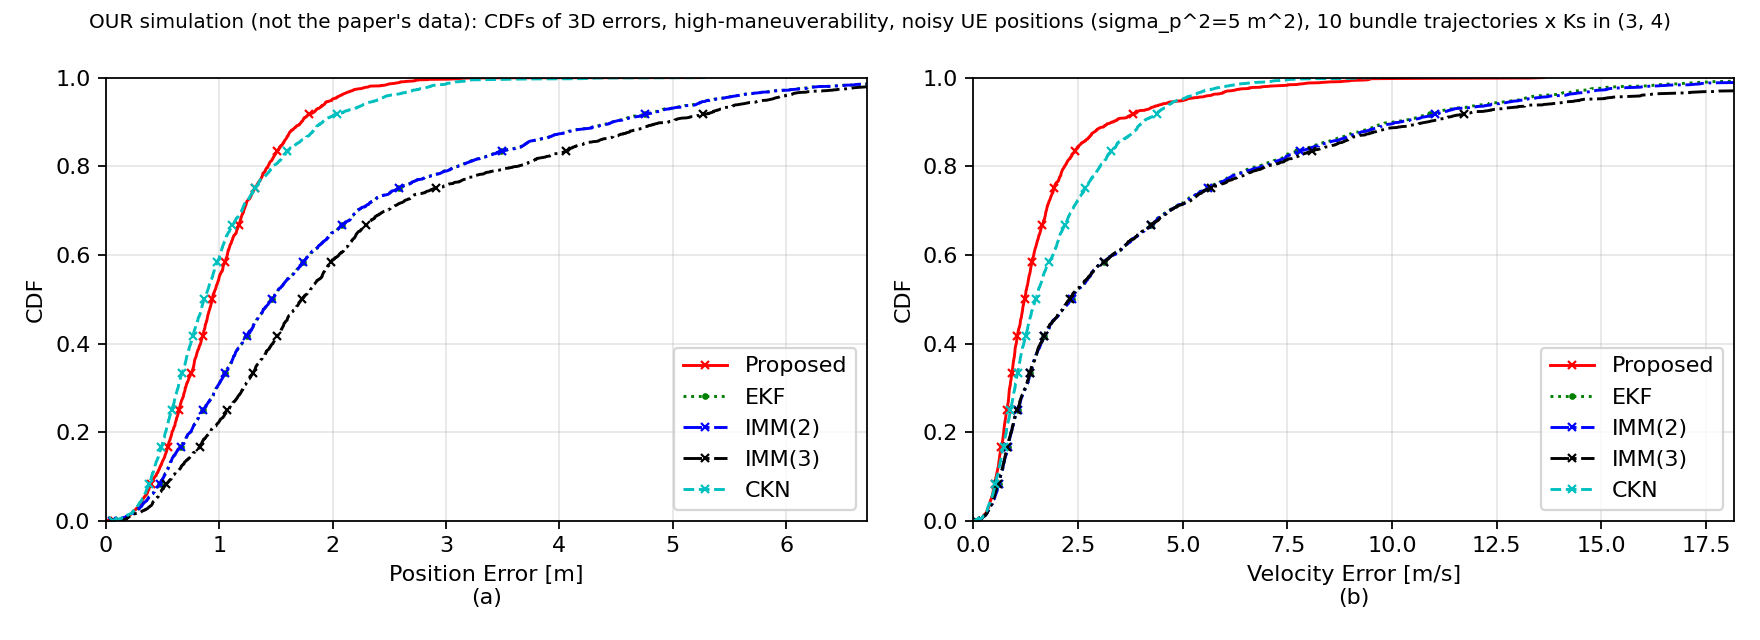

,Method,Pos RMSE [m],Vel RMSE [m/s],Pos median [m],Vel median [m/s],Pos RMSE Ks=3,Vel RMSE Ks=3,Pos RMSE Ks=4,Vel RMSE Ks=4,"Latency [ms/step, 128 traj]"
0,Proposed,1.152,2.320,0.936,1.229,1.192,2.576,1.112,2.031,4.443
1,EKF,2.531,5.714,1.465,2.339,2.636,6.974,2.422,4.082,2.357
2,IMM(2),2.536,5.825,1.465,2.338,2.643,7.113,2.424,4.154,152.081
3,IMM(3),2.830,6.555,1.730,2.304,2.728,7.833,2.929,4.958,239.413
4,CKN,1.228,2.461,0.866,1.501,1.258,2.723,1.197,2.167,3.447


In [ ]:
from IPython.display import Image, display
import pandas as pd
display(Image('/content/work_fig5/fig5_reproduction.png'))
pd.read_csv('/content/work_fig5/results_table.csv').round(3)

**Reading it:** curves further left/higher are better. Compare EKF, IMM, CKN and Proposed (the paper's learning-aided EKF). Don't call a small gap real without the confidence intervals in Part C. For final numbers rerun Part B with `--preset full` and `--work /content/work_fig5_full`.

## Part C. Ablation (Fig. 6 idea) and confidence intervals

In [ ]:
!python run_ablation.py --work /content/work_fig5 --preset fast    # full vs EKF+prediction vs EKF+update vs EKF

[EKF+update only] it    0 loss  16.861 (pos 3.94 vel 7.13 nll   289.7) | val pos+vel RMSE 7.944 (best 7.944) | 1s
[EKF+update only] it   20 loss  11.751 (pos 3.02 vel 6.12 nll   130.2) | val pos+vel RMSE 7.721 (best 7.721) | 15s
[EKF+update only] it   40 loss  10.269 (pos 2.93 vel 5.31 nll   101.5) | val pos+vel RMSE 7.247 (best 7.247) | 28s
[EKF+update only] it   60 loss   9.690 (pos 2.57 vel 5.78 nll    67.2) | val pos+vel RMSE 6.825 (best 6.825) | 41s
[EKF+update only] it   80 loss   7.762 (pos 2.10 vel 4.52 nll    56.8) | val pos+vel RMSE 6.574 (best 6.574) | 54s
[EKF+update only] it  100 loss   8.226 (pos 2.34 vel 4.63 nll    62.8) | val pos+vel RMSE 6.458 (best 6.458) | 67s
[EKF+update only] it  119 loss   8.541 (pos 2.60 vel 4.50 nll    72.5) | val pos+vel RMSE 6.410 (best 6.410) | 81s
Full learning-aided EKF    pos RMSE 1.152 m | vel RMSE 2.320 m/s
EKF+prediction             pos RMSE 1.402 m | vel RMSE 2.473 m/s
EKF+update                 pos RMSE 1.802 m | vel RMSE 3.992 m/s
E

In [ ]:
!python run_stats.py --work /content/work_fig5 --ntraj 10         # bootstrap 95% CIs (resampling whole trajectories)

Full learning-aided EKF    pos RMSE 1.15 [1.04, 1.26]   vel RMSE 2.32 [1.39, 3.39]
EKF+prediction             pos RMSE 1.40 [1.27, 1.53]   vel RMSE 2.47 [1.51, 3.57]
EKF+update                 pos RMSE 1.80 [1.32, 2.21]   vel RMSE 3.99 [3.07, 4.75]
EKF                        pos RMSE 2.53 [1.80, 3.25]   vel RMSE 5.71 [4.00, 7.27]


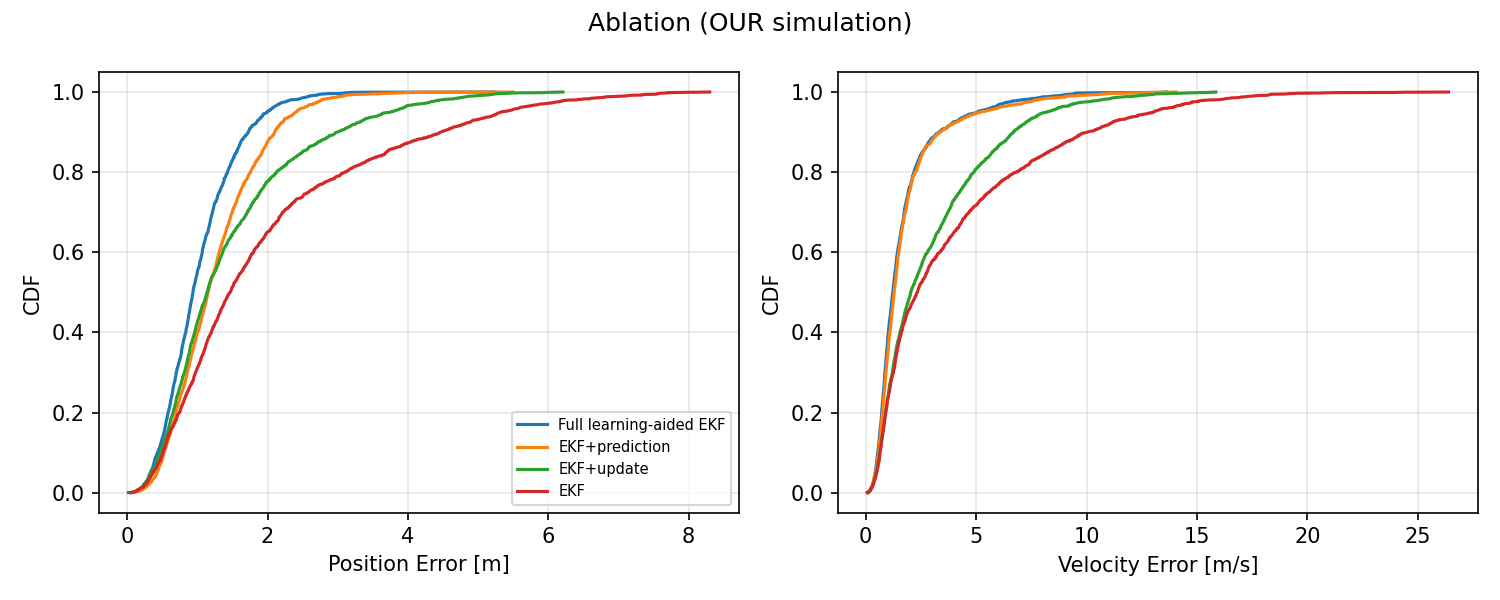

In [ ]:
display(Image('/content/work_fig5/fig_ablation.png'))

## Part D. Novelty: UE motion vs the paper's zero-Doppler clutter assumption
The paper assumes static UEs, so clutter sits at zero Doppler and a fixed notch removes it. We simulate moving UEs (0, 1.5, 5, 10, 20 m/s) with a signal-level model and compare: no removal, the paper's notch, a map-free wide notch, our UE-motion-aware filter, and an oracle. Cached per speed, so it can resume.

In [ ]:
!python run_clutter.py --bundle /content/bundle --work /content/work_clutter --ntraj 10 --stage sweep --sens

  speed   0.0 m/s  traj 1/10  14s
  speed   0.0 m/s  traj 2/10  26s
  speed   0.0 m/s  traj 3/10  38s
  speed   0.0 m/s  traj 4/10  50s
  speed   0.0 m/s  traj 5/10  63s
  speed   0.0 m/s  traj 6/10  75s
  speed   0.0 m/s  traj 7/10  87s
  speed   0.0 m/s  traj 8/10  100s
  speed   0.0 m/s  traj 9/10  112s
  speed   0.0 m/s  traj 10/10  124s
  speed   1.5 m/s  traj 1/10  11s
  speed   1.5 m/s  traj 2/10  23s
  speed   1.5 m/s  traj 3/10  34s
  speed   1.5 m/s  traj 4/10  45s
  speed   1.5 m/s  traj 5/10  57s
  speed   1.5 m/s  traj 6/10  68s
  speed   1.5 m/s  traj 7/10  80s
  speed   1.5 m/s  traj 8/10  91s
  speed   1.5 m/s  traj 9/10  103s
  speed   1.5 m/s  traj 10/10  114s
  speed   5.0 m/s  traj 1/10  11s
  speed   5.0 m/s  traj 2/10  23s
  speed   5.0 m/s  traj 3/10  35s
  speed   5.0 m/s  traj 4/10  46s
  speed   5.0 m/s  traj 5/10  57s
  speed   5.0 m/s  traj 6/10  69s
  speed   5.0 m/s  traj 7/10  80s
  speed   5.0 m/s  traj 8/10  92s
  speed   5.0 m/s  traj 9/10  103s
  spee

In [ ]:
!python run_clutter.py --bundle /content/bundle --work /content/work_clutter --ntraj 10 --stage report

velocity-measurement sigma by dataset SNR level (from static-UE paper pipeline): {0: 1.0947537764059465, 5: 0.9619138292844287, 10: 0.8060748342540517, 20: 0.519048271981848}
EKF q tuned at UE speed 0.0 with paper filter: 0.3  {0.03: 7.17, 0.1: 6.16, 0.3: 6.03, 1.0: 6.6, 3.0: 7.67, 10.0: 9.32, 30.0: 11.09}
EKF-without-Doppler q tuned: 10.0  {0.1: 8.36, 0.3: 7.48, 1.0: 6.84, 3.0: 6.42, 10.0: 6.27, 30.0: 6.69, 100.0: 8.14}

 ue_speed     method  out_clutter_dB  detected  correct_det  false_alarm  valid_vel_rmse  pos_rmse  vel_rmse
      0.0       none           23.53      1.00         0.13         0.87            1.16     14.86     11.33
      0.0   paper_dc         -281.27      0.86         0.58         0.28            0.80      2.25      3.78
      0.0 band_notch          -17.97      0.70         0.47         0.22            0.79      2.18      4.42
      0.0   ue_aware          -15.80      0.91         0.55         0.36            0.85      2.39      3.52
      0.0     oracle         

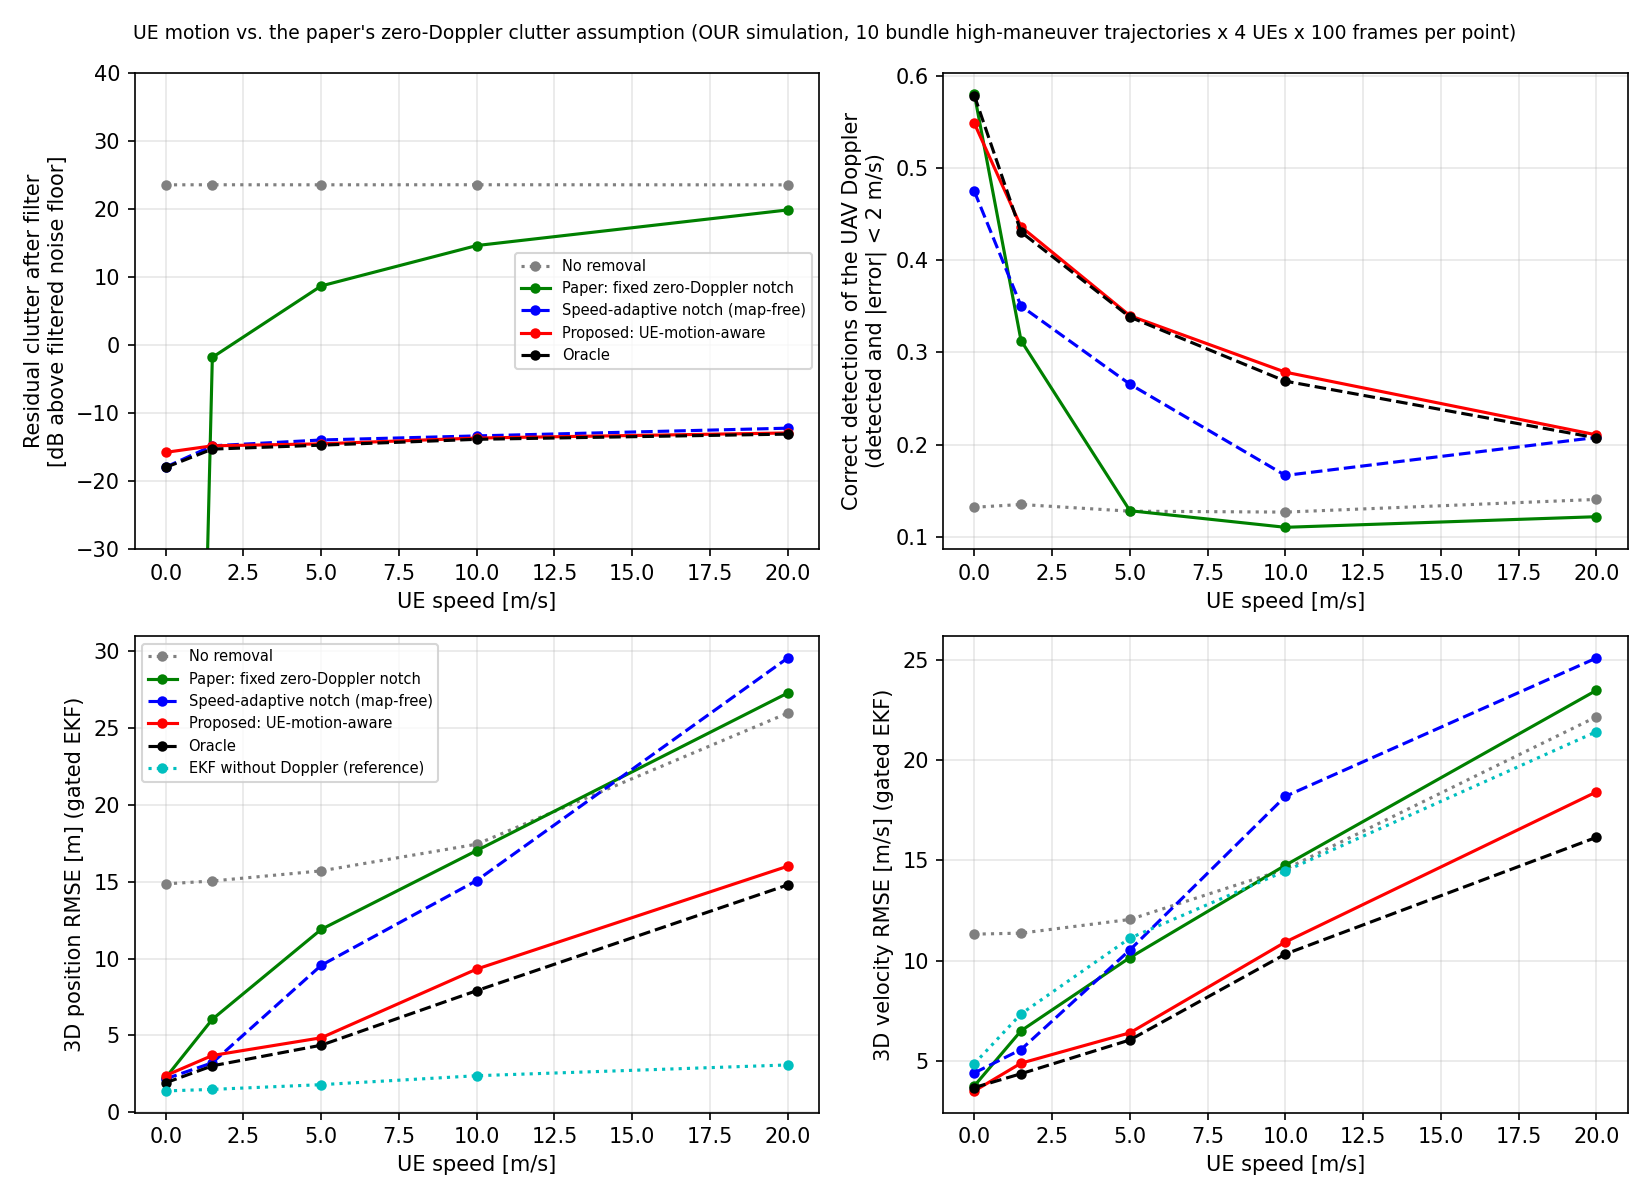

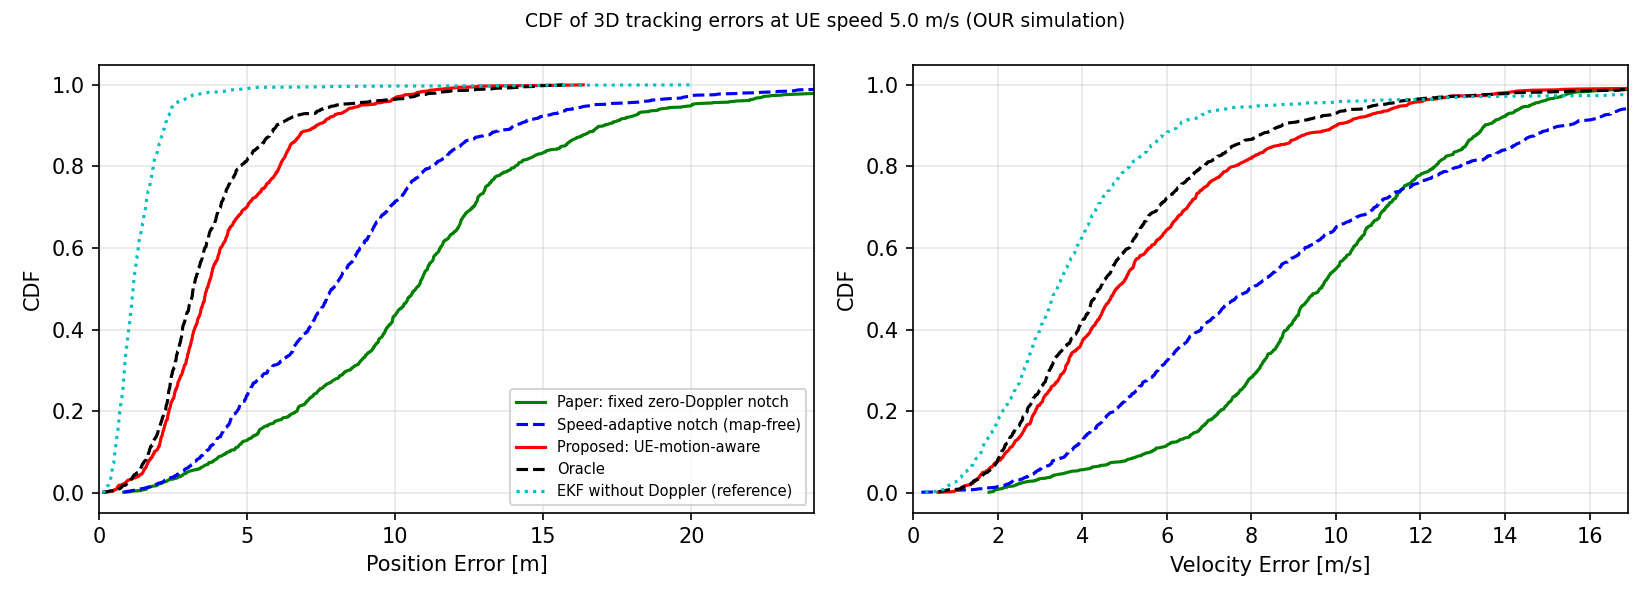

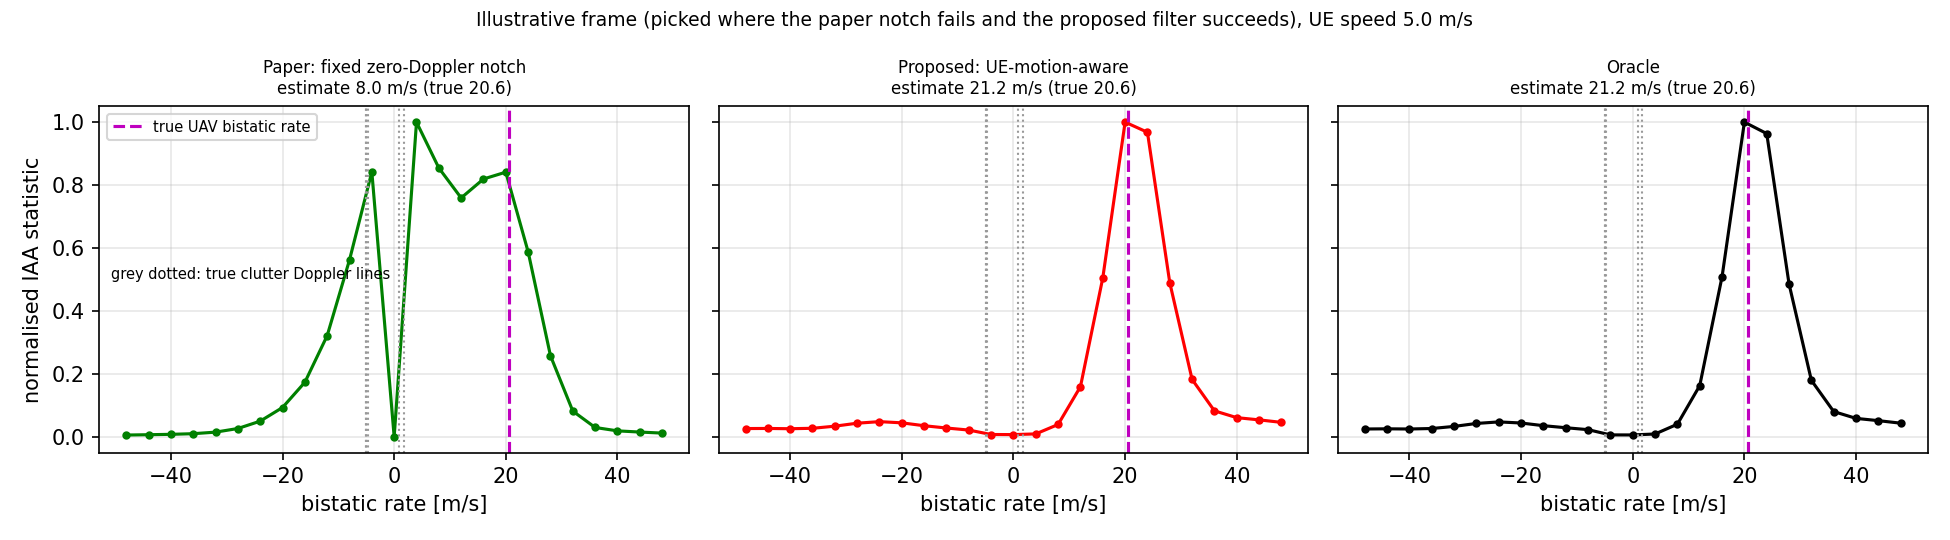

,ue_speed,method,out_clutter_dB,detected,correct_det,false_alarm,valid_vel_rmse,pos_rmse,vel_rmse
0,0.0,none,23.53,1.00,0.13,0.87,1.16,14.86,11.33
1,0.0,paper_dc,-281.27,0.86,0.58,0.28,0.80,2.25,3.78
2,0.0,band_notch,-17.97,0.70,0.47,0.22,0.79,2.18,4.42
3,0.0,ue_aware,-15.80,0.91,0.55,0.36,0.85,2.39,3.52
4,0.0,oracle,-18.01,0.86,0.58,0.28,0.78,1.92,3.69
5,0.0,no_doppler,NaN,NaN,NaN,NaN,NaN,1.39,4.88
6,1.5,none,23.53,1.00,0.14,0.86,1.12,15.05,11.38
7,1.5,paper_dc,-1.84,1.00,0.31,0.69,1.11,6.05,6.52
8,1.5,band_notch,-14.84,0.70,0.35,0.35,0.90,3.22,5.58
9,1.5,ue_aware,-14.84,0.81,0.44,0.37,0.87,3.70,4.90


In [ ]:
for f in ('fig_clutter_vs_ue_speed','fig_clutter_cdf','fig_clutter_spectrum'): display(Image(f'/content/work_clutter/{f}.png'))
pd.read_csv('/content/work_clutter/clutter_results.csv').round(2)

## Part E. Paper pipeline vs our pipeline
{paper notch, our UE-aware filter} x {gated EKF, learning-aided EKF}. A separate learning-aided EKF is trained for each front-end. Needs Part D finished (it reads `/content/work_clutter/speed_*.pkl`).

In [ ]:
!python run_tracking_compare.py --test_work /content/work_clutter --work /content/work_track --preset fast --stage data     # new train/val trajectories through the signal pipeline (slowest)

train speed 0.0: 24 trajectories, 111s
train speed 1.5: 24 trajectories, 111s
train speed 5.0: 24 trajectories, 111s
train speed 10.0: 24 trajectories, 113s
train speed 20.0: 24 trajectories, 111s
val speed 0.0: 8 trajectories, 37s
val speed 1.5: 8 trajectories, 37s
val speed 5.0: 8 trajectories, 37s
val speed 10.0: 8 trajectories, 37s
val speed 20.0: 8 trajectories, 37s


In [ ]:
!python run_tracking_compare.py --test_work /content/work_clutter --work /content/work_track --preset fast --stage train    # one learning-aided EKF per front-end

calibration (validation, UE speed 0.0): sigma_v by SNR {0: 1.0454820190314016, 5: 1.0110705457351143, 10: 0.7945224115582119, 20: 0.5233425560577015}, EKF q 0.3, no-Doppler q 10.0
[paper_dc stage1 prediction] it    0 loss  10.911 (pos 1.81 vel 7.37 nll    86.5) | val pos+vel RMSE 17.371 (best 17.371) | 1s
[paper_dc stage1 prediction] it   25 loss   9.246 (pos 2.42 vel 5.31 nll    75.8) | val pos+vel RMSE 16.447 (best 16.447) | 17s
[paper_dc stage1 prediction] it   50 loss   8.652 (pos 2.52 vel 4.76 nll    68.6) | val pos+vel RMSE 16.486 (best 16.447) | 33s
[paper_dc stage1 prediction] it   75 loss   8.379 (pos 2.53 vel 4.52 nll    66.6) | val pos+vel RMSE 16.502 (best 16.447) | 48s
[paper_dc stage1 prediction] it   99 loss 145.256 (pos 32.56 vel 21.81 nll  4544.3) | val pos+vel RMSE 16.430 (best 16.430) | 63s
[paper_dc stage2 update] it    0 loss   8.020 (pos 2.46 vel 4.38 nll    58.9) | val pos+vel RMSE 16.197 (best 16.197) | 2s
[paper_dc stage2 update] it   25 loss   6.707 (pos 1.93 

In [ ]:
!python run_tracking_compare.py --test_work /content/work_clutter --work /content/work_track --preset fast --stage eval     # table + figures + gain summary

calibration (validation, UE speed 0.0): sigma_v by SNR {0: 1.0454820190314016, 5: 1.0110705457351143, 10: 0.7945224115582119, 20: 0.5233425560577015}, EKF q 0.3, no-Doppler q 10.0

 ue_speed front_end tracker  pos_rmse  vel_rmse  pos_median  vel_median
      0.0  paper_dc     EKF      2.25      3.78        1.34        2.87
      0.0  paper_dc      LA      1.76      4.09        1.31        2.47
      0.0  ue_aware     EKF      2.42      3.55        1.68        2.85
      0.0  ue_aware      LA      1.55      3.08        1.20        2.36
      0.0      none     ref      1.38      4.51        1.11        3.32
      1.5  paper_dc     EKF      6.08      6.56        5.30        5.16
      1.5  paper_dc      LA      2.07      5.50        1.66        3.69
      1.5  ue_aware     EKF      3.70      4.93        2.52        3.71
      1.5  ue_aware      LA      1.63      4.88        1.25        2.74
      1.5      none     ref      1.41      5.31        1.12        3.32
      5.0  paper_dc     EKF

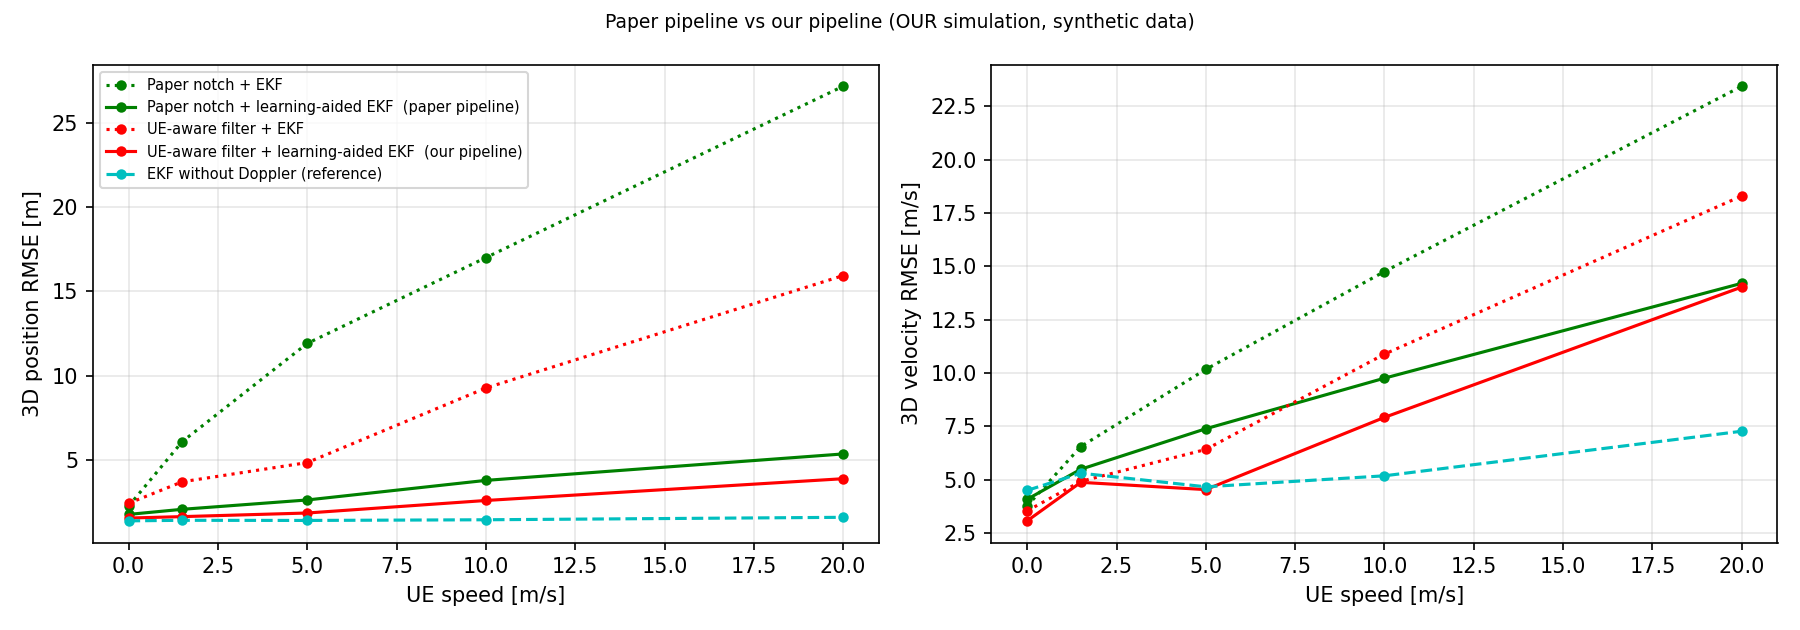

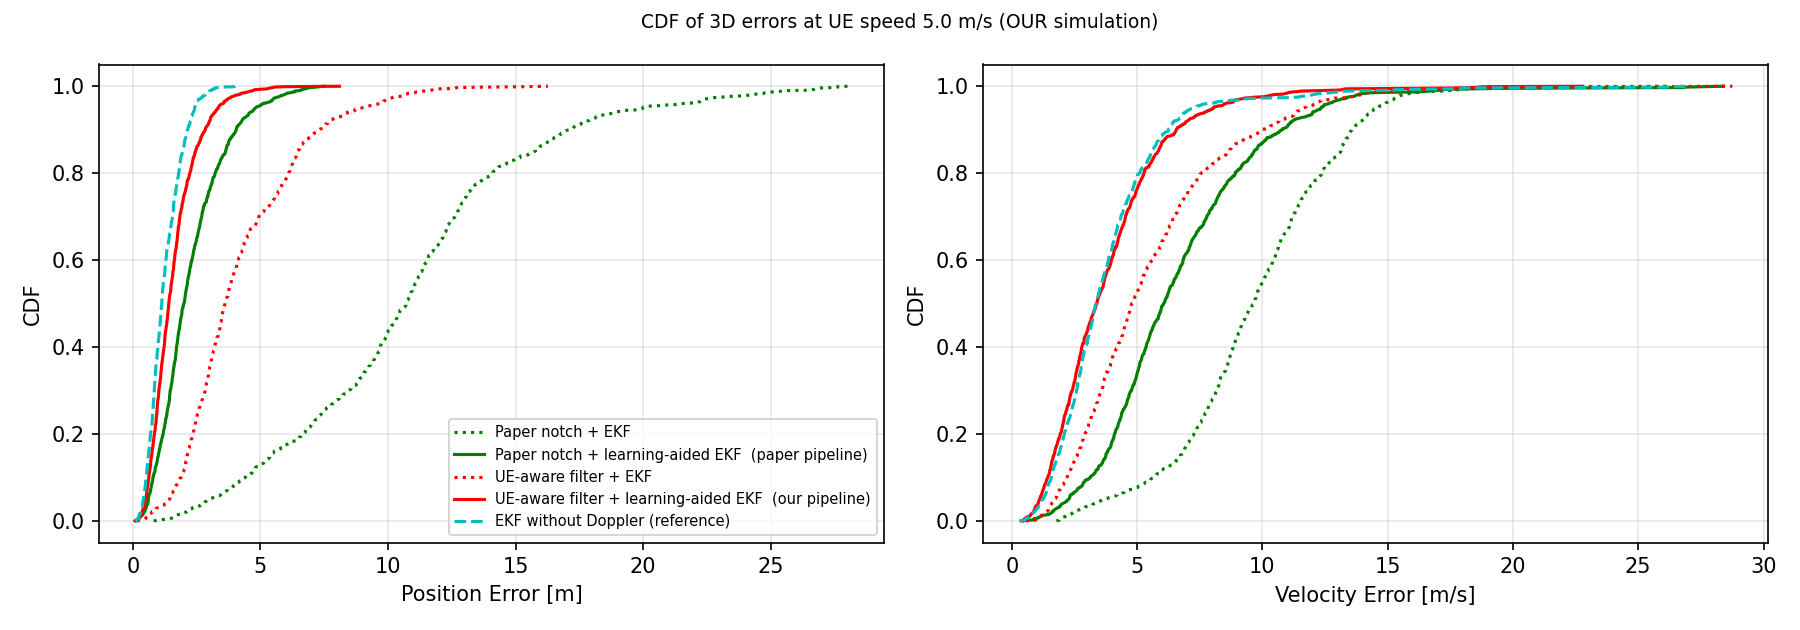

,ue_speed,front_end,tracker,pos_rmse,vel_rmse,pos_median,vel_median
0,0.0,paper_dc,EKF,2.25,3.78,1.34,2.87
1,0.0,paper_dc,LA,1.76,4.09,1.31,2.47
2,0.0,ue_aware,EKF,2.42,3.55,1.68,2.85
3,0.0,ue_aware,LA,1.55,3.08,1.20,2.36
4,0.0,none,ref,1.38,4.51,1.11,3.32
5,1.5,paper_dc,EKF,6.08,6.56,5.30,5.16
6,1.5,paper_dc,LA,2.07,5.50,1.66,3.69
7,1.5,ue_aware,EKF,3.70,4.93,2.52,3.71
8,1.5,ue_aware,LA,1.63,4.88,1.25,2.74
9,1.5,none,ref,1.41,5.31,1.12,3.32


In [ ]:
for f in ('fig_pipeline_compare','fig_pipeline_cdf'): display(Image(f'/content/work_track/{f}.png'))
pd.read_csv('/content/work_track/tracking_compare.csv').round(2)

For final numbers rerun Part E with `--preset full` and `--work /content/work_track_full`.

## Part F. Save results to Drive (Colab deletes /content when the runtime resets)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/uav_isac_results
!cp -r /content/work_fig5* /content/work_clutter /content/work_track* /content/drive/MyDrive/uav_isac_results/ 2>/dev/null; ls /content/drive/MyDrive/uav_isac_results

Mounted at /content/drive
work_clutter  work_fig5  work_track
